# Random Forest T+1 — WIN

O objetivo é prever o retorno do próximo candle do mini-índice com Random Forest e encontrar o melhor cenário, decidindo um grupo de parâmetros por vez.

| Passo | Decide | Status |
|---|---|---|
| 1 | tamanho do candle | neste notebook |
| 2 | features | neste notebook |
| 3 | janela de treino e periodicidade de retreino | neste notebook |
| 4 | hiperparâmetros | neste notebook |
| 5 | regras de compra e venda | próximo |
| 6 | confirmação, congelamento e validação (01/2025 → 03/2026) | próximo |

Cada passo usa o resultado dos anteriores (variáveis em memória ou os arquivos em `resultados/`). Rode as células em ordem: *Ambiente de execução → Executar tudo*.

# Passo 1 — Escolha do candle (Random Forest, previsão T+1 do WIN)

**Pergunta:** qual tamanho de candle (1, 5, 15, 30 ou 60 min) dá a melhor base para prever o retorno do próximo candle?

O passo tem duas partes:

1. **Análise de dados (sem modelo, só dados até 31/12/2023).** Quanto o preço anda em cada candle frente ao custo, se existe memória de um candle para o próximo (ρ₁) e quanta informação as features básicas carregam.
2. **Modelo (seleção em 2024).** Um RF fixo e simples treinado em cada candle, com tudo o mais igual: janela de 12 meses, re-treino trimestral e as mesmas features.

| Fixo neste passo | Valor |
|---|---|
| Alvo | $r_{t+1} = 100 \cdot \ln(C_{t+1}/C_t)$, só dentro do mesmo pregão |
| Janela de treino | 12 meses (revista no passo 3) |
| Re-treino | trimestral, em 2024 |
| Features | básicas: `ret_0`, `ret_1`, `ret_2`, `vol_20`, `hora` (revistas no passo 2) |
| RF | 200 árvores, profundidade 5, 1% do treino por folha (revisto no passo 4) |
| Custo | 5 pts por operação completa |
| Não usado | 01/2025 → 03/2026 (validação final) |

**Critério de decisão** (definido antes de rodar):
1. **Filtro:** Theil U ≤ 1,001 em 2024. Até 0,1% pior que prever zero conta como empate.
2. **Ranking:** maior correlação de Spearman entre os candles com **t robusto > 2**.
3. **Desempate:** estabilidade entre os meses e folga entre o ganho bruto por operação e o custo.
4. Se nenhum candle tiver t robusto > 2, fica o de maior Spearman, registrando que não há sinal significativo.

### Como rodar no Colab
1. Suba o arquivo `WIN$N_M1.csv` para o seu Google Drive (por exemplo, em `MyDrive/data_science_v2/`).
2. Ajuste `CAMINHO_CSV_DRIVE` na célula de configuração, se precisar.
3. *Ambiente de execução → Executar tudo*. Leva cerca de 5 min sem a checagem de robustez e de 10 a 15 min com ela.

Se preferir não usar o Drive, mude `FONTE = "upload"`: a célula abre um seletor de arquivo. O upload de ~47 MB demora.

## 0. Configuração

In [1]:
# ===== CONFIGURAÇÃO =====
FONTE = "drive"                      # "drive" | "upload" | "local"
CAMINHO_CSV_DRIVE = "/content/drive/MyDrive/data_science_v2/WIN$N_M1.csv"

CANDLES = [1, 5, 15, 30, 60]         # minutos
JANELA_MESES = 12                    # janela de treino fixa neste passo
RODAR_ROBUSTEZ = True                # repete o modelo com janelas de 6 e 24 meses
JANELAS_ROBUSTEZ = [6, 24]

FIM_EXPLORACAO = "2023-12-31"        # análise de dados só até aqui
ANO_SELECAO = 2024
CUSTO_PTS = 5.0
TOL_THEIL = 1.001                    # U <= 1,001 conta como empate com o naive
SEED = 42

RF_PARAMS = dict(n_estimators=200, max_depth=5, min_samples_leaf=0.01,
                 max_features=1.0, max_samples=0.5, n_jobs=-1, random_state=SEED)
FEATURES = ["ret_0", "ret_1", "ret_2", "vol_20", "hora"]

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CORES = {1: "#4C78A8", 5: "#F58518", 15: "#54A24B", 30: "#B279A2", 60: "#E45756"}

try:
    import google.colab  # noqa: F401
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

def localiza_csv():
    """Tenta, em ordem: Drive -> CSV enviado pelo painel lateral (/content) -> upload -> pasta local."""
    nome = "WIN$N_M1.csv"
    if NO_COLAB:
        if FONTE == "drive":
            try:
                from google.colab import drive
                drive.mount("/content/drive")
                if Path(CAMINHO_CSV_DRIVE).exists():
                    return Path(CAMINHO_CSV_DRIVE)
                print(f"Drive montado, mas o arquivo não está em {CAMINHO_CSV_DRIVE}. Procurando no Drive...")
                achados = list(Path("/content/drive/MyDrive").rglob(nome))
                if achados:
                    print("Encontrado em:", achados[0])
                    return achados[0]
            except Exception as erro:
                print(f"Não foi possível montar o Drive ({erro}).")
                print("Alternativa: envie o CSV pelo ícone de pasta à esquerda (Arquivos -> Fazer upload).")
        enviado_painel = Path("/content") / nome
        if enviado_painel.exists():
            return enviado_painel
        from google.colab import files
        print("Selecione o arquivo WIN$N_M1.csv:")
        enviado = files.upload()
        return Path("/content") / next(iter(enviado))
    return next(p / nome for p in [Path.cwd(), Path.cwd().parent] if (p / nome).exists())


ARQ_WIN = localiza_csv()

PASTA_RES = ARQ_WIN.parent / "resultados"
PASTA_RES.mkdir(exist_ok=True)
print("CSV:", ARQ_WIN)
print("Resultados em:", PASTA_RES)

CSV: C:\Users\anabi\AppData\Local\Temp\claude\7443c3ed6403f415\e018eed5-a243-4290-aadd-86ab9ea34b5d\scratchpad\rerun\WIN$N_M1.csv
Resultados em: C:\Users\anabi\AppData\Local\Temp\claude\7443c3ed6403f415\e018eed5-a243-4290-aadd-86ab9ea34b5d\scratchpad\rerun\resultados


## 1. Carregar os candles de 1 minuto

757,711 candles de 1 min · 2020-10-15 11:49:00 -> 2026-09-25 18:24:00 · 1368 pregões


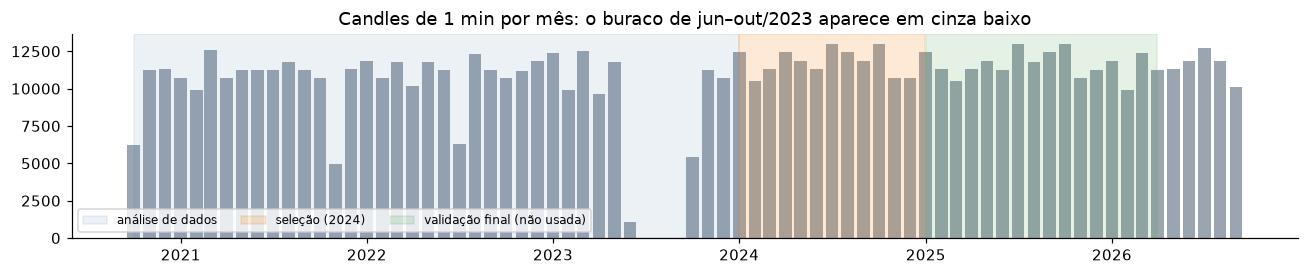

In [3]:
m1 = pd.read_csv(ARQ_WIN, sep="\t")
m1.columns = [c.strip("<>").lower() for c in m1.columns]
m1["dt"] = pd.to_datetime(m1["date"] + " " + m1["time"], format="%Y.%m.%d %H:%M:%S")
m1 = m1.drop(columns=["date", "time", "spread"]).set_index("dt").sort_index()
m1 = m1[~m1.index.duplicated()]
m1 = m1.between_time("09:00", "18:24")          # só o pregão regular

print(f"{len(m1):,} candles de 1 min · {m1.index.min()} -> {m1.index.max()} · "
      f"{m1.index.normalize().nunique()} pregões")

cob = m1.groupby(m1.index.to_period("M")).size()
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.bar(cob.index.to_timestamp(), cob.values, width=25, color="#9aa5b1")
ax.axvspan(pd.Timestamp("2020-10-01"), pd.Timestamp(FIM_EXPLORACAO), color="#4C78A8", alpha=0.10, label="análise de dados")
ax.axvspan(pd.Timestamp(f"{ANO_SELECAO}-01-01"), pd.Timestamp(f"{ANO_SELECAO}-12-31"), color="#F58518", alpha=0.18, label="seleção (2024)")
ax.axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2026-03-31"), color="#54A24B", alpha=0.15, label="validação final (não usada)")
ax.set_title("Candles de 1 min por mês: o buraco de jun–out/2023 aparece em cinza baixo")
ax.legend(loc="lower left", fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## 2. Montar as bases de cada candle

- Cada candle de *k* minutos é formado **dentro do pregão**, alinhado ao relógio (9:00, 9:30, ...).
- **Alvo:** retorno do próximo candle do mesmo pregão. O último candle do dia fica sem alvo, para o par não atravessar a noite.
- **Features (só até t):**
  - `ret_0..2`: retorno do candle atual e dos dois anteriores; valem 0 no começo do dia, para não usar o gap de abertura.
  - `vol_20`: desvio dos últimos 20 retornos intradiários.
  - `hora`: horário do candle em horas decimais.
- `pts_prox` $= C_{t+1} - C_t$, em pontos, usado nas contas de custo.

In [4]:
def agrega_candles(m1, minutos):
    if minutos == 1:
        return m1.copy()
    regras = {"open": "first", "high": "max", "low": "min", "close": "last", "tickvol": "sum", "vol": "sum"}
    out = m1.resample(f"{minutos}min", label="left", closed="left").agg(regras)
    return out.dropna(subset=["close"])


def monta_base(m1, minutos):
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    ret = 100 * np.log(df["close"]).groupby(dia).diff()      # NaN no 1º candle do dia

    df["tem_ret_0"] = ret.notna()                             # usado no ρ₁ (exclui o 1º candle)
    df["ret_0"] = ret
    df["ret_1"] = ret.groupby(dia).shift(1)
    df["ret_2"] = ret.groupby(dia).shift(2)
    df["vol_20"] = ret.rolling(20, min_periods=10).std()
    df["hora"] = df.index.hour + df.index.minute / 60
    df["alvo"] = ret.groupby(dia).shift(-1)
    df["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]
    df[["ret_0", "ret_1", "ret_2"]] = df[["ret_0", "ret_1", "ret_2"]].fillna(0.0)
    return df.dropna(subset=["alvo", "vol_20"])


bases = {k: monta_base(m1, k) for k in CANDLES}
for k, b in bases.items():
    print(f"{k:>3} min: {len(b):>8,} linhas · {b.index.min().date()} -> {b.index.max().date()}")

  1 min:  756,333 linhas · 2020-10-15 -> 2026-09-25
  5 min:  150,285 linhas · 2020-10-15 -> 2026-09-25
 15 min:   49,642 linhas · 2020-10-15 -> 2026-09-25
 30 min:   24,135 linhas · 2020-10-15 -> 2026-09-25
 60 min:   11,865 linhas · 2020-10-16 -> 2026-09-25


## 3. Análise de dados (até 31/12/2023, sem modelo)

### 3.1 Tamanho do movimento contra o custo

Para uma previsão com correlação ρ com a variação seguinte, operar o sinal da previsão rende, em média, cerca de $\rho \cdot \sigma_{pts} \cdot \sqrt{2/\pi}$ pontos por operação (aproximação normal). Daí sai a **correlação necessária para pagar o custo**:

$$\rho_{necessário} = \frac{\text{custo}}{\sigma_{pts} \cdot 0{,}798}$$

Candles maiores andam mais, então o custo pesa menos e o ρ necessário cai. Em compensação, há menos amostras.

In [5]:
def explo(b):
    return b[b.index <= FIM_EXPLORACAO]

linhas = []
for k, b in bases.items():
    e = explo(b)
    sig_pts = e["pts_prox"].std()
    linha = {
        "candle_min": k,
        "linhas_ate_2023": len(e),
        "candles_por_dia": e.groupby(e.index.normalize()).size().median(),
        "desvio_ret_%": e["alvo"].std(),
        "desvio_pts": sig_pts,
        "mov_medio_abs_pts": e["pts_prox"].abs().mean(),
        "custo5_sobre_mov_%": 100 * CUSTO_PTS / e["pts_prox"].abs().mean(),
    }
    for c in [CUSTO_PTS]:
        linha[f"rho_nec_{c:g}pts"] = c / (sig_pts * np.sqrt(2 / np.pi))
    linhas.append(linha)

tab_mov = pd.DataFrame(linhas).set_index("candle_min")
tab_mov.style.format({
    "linhas_ate_2023": "{:,.0f}", "candles_por_dia": "{:.0f}", "desvio_ret_%": "{:.4f}",
    "desvio_pts": "{:.1f}", "mov_medio_abs_pts": "{:.1f}", "custo5_sobre_mov_%": "{:.1f}%",
    "rho_nec_5pts": "{:.3f}",
})

,linhas_ate_2023,candles_por_dia,desvio_ret_%,desvio_pts,mov_medio_abs_pts,custo5_sobre_mov_%,rho_nec_5pts
candle_min,,,,,,,
1,"371,487",534,0.0522,58.5,40.7,12.3%,0.107
5,"73,778",106,0.1147,128.6,91.7,5.5%,0.049
15,"24,364",35,0.1961,219.8,156.7,3.2%,0.029
30,"11,837",17,0.2791,312.7,223.7,2.2%,0.020
60,"5,715",8,0.3932,440.8,317.6,1.6%,0.014


### 3.2 Memória de um candle para o próximo (ρ₁)

ρ₁ = correlação entre o retorno do candle atual e o do seguinte, no mesmo pregão (sem o 1º candle do dia).

Dois erros-padrão:
- **simples**, $1/\sqrt{n}$;
- **robusto**, que considera que a volatilidade vem em grupos. Com $z$ = retornos padronizados, $\hat\rho = \overline{z_t z_{t+1}}$ e $EP = \text{desvio}(z_t z_{t+1})/\sqrt{n}$.

Se ρ₁ ficar dentro da faixa robusta, não há memória utilizável **na forma linear**. O RF ainda pode achar relações não lineares ou condicionais.

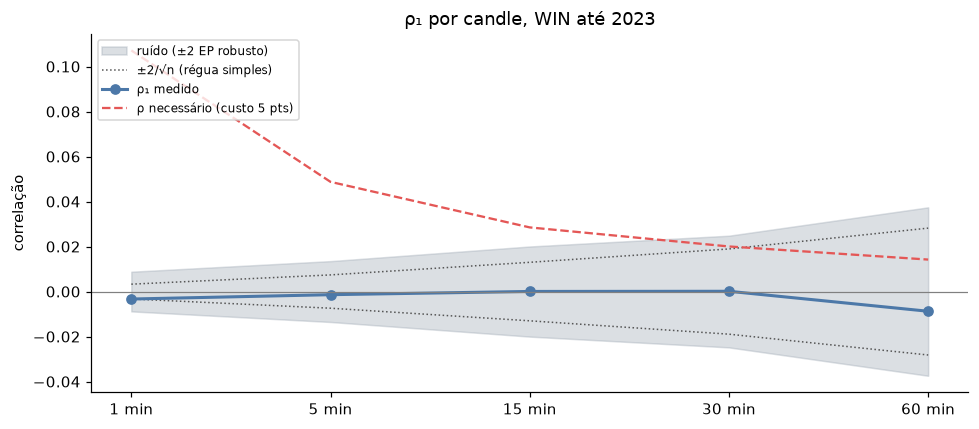

,n,rho1,ep_robusto,ep_simples,t_robusto,rho_nec_5pts
candle_min,,,,,,
1,370805,-0.0033,0.0044,0.0016,-0.7539,0.1072
5,73096,-0.0014,0.0068,0.0037,-0.2053,0.0487
15,23682,0.0000,0.0100,0.0065,0.0048,0.0285
30,11155,0.0001,0.0124,0.0095,0.0100,0.0200
60,5034,-0.0088,0.0187,0.0141,-0.4678,0.0142


In [6]:
def rho_robusto(x, y):
    zx = (x - x.mean()) / x.std()
    zy = (y - y.mean()) / y.std()
    prod = zx * zy
    n = len(prod)
    return prod.mean(), prod.std(ddof=1) / np.sqrt(n), 1 / np.sqrt(n), n

linhas = []
for k, b in bases.items():
    e = explo(b)
    e = e[e["tem_ret_0"]]
    rho, ep_rob, ep_simp, n = rho_robusto(e["ret_0"].values, e["alvo"].values)
    linhas.append({"candle_min": k, "n": n, "rho1": rho, "ep_robusto": ep_rob, "ep_simples": ep_simp,
                   "t_robusto": rho / ep_rob, "rho_nec_5pts": tab_mov.loc[k, "rho_nec_5pts"]})
tab_rho1 = pd.DataFrame(linhas).set_index("candle_min")

x = np.arange(len(CANDLES))
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(x, -2 * tab_rho1["ep_robusto"], 2 * tab_rho1["ep_robusto"], color="#9aa5b1", alpha=0.35, label="ruído (±2 EP robusto)")
ax.plot(x, 2 * tab_rho1["ep_simples"], ls=":", color="#555", lw=1, label="±2/√n (régua simples)")
ax.plot(x, -2 * tab_rho1["ep_simples"], ls=":", color="#555", lw=1)
ax.plot(x, tab_rho1["rho1"], "o-", color="#4C78A8", lw=2, label="ρ₁ medido")
ax.plot(x, tab_rho1["rho_nec_5pts"], "--", color="#E45756", label="ρ necessário (custo 5 pts)")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [f"{k} min" for k in CANDLES])
ax.set_ylabel("correlação")
ax.set_title("ρ₁ por candle, WIN até 2023")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
tab_rho1.round(4)

### 3.3 Informação das features básicas, por candle

Duas medidas de quanto cada feature diz sobre o alvo, até 2023:
- **Spearman:** relação monotônica, com sinal;
- **informação mútua:** qualquer relação, inclusive não linear. Zero significa nenhuma informação. Calculada numa amostra de até 50 mil linhas.

As features de volatilidade costumam ter Spearman perto de zero e informação mútua positiva. Elas informam o **tamanho** do próximo movimento, não a direção.

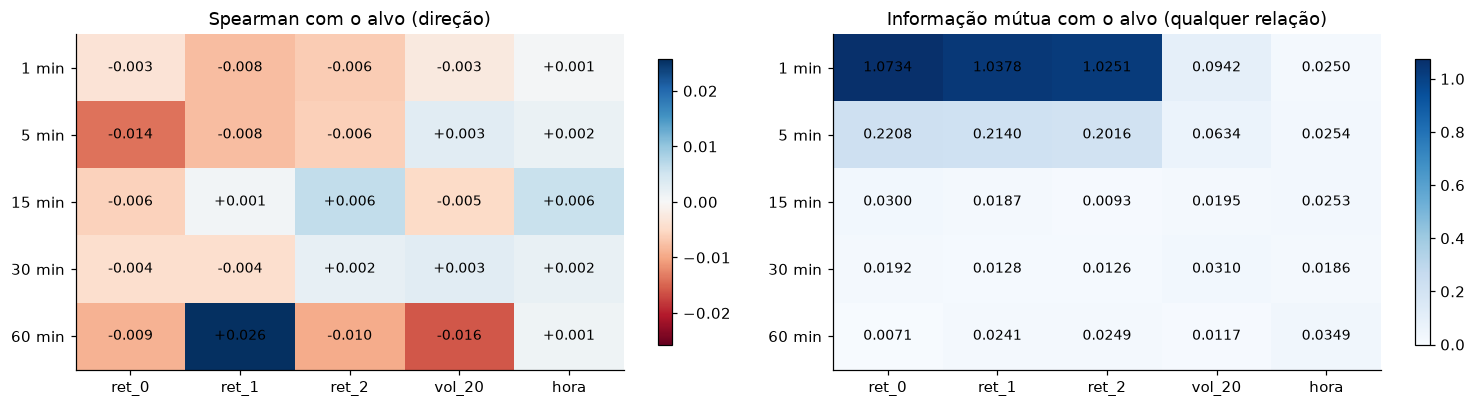

In [7]:
rng = np.random.default_rng(SEED)
sp, mi = {}, {}
for k, b in bases.items():
    e = explo(b)
    sp[k] = {f: spearmanr(e[f], e["alvo"])[0] for f in FEATURES}
    amostra = e.iloc[rng.choice(len(e), size=min(50_000, len(e)), replace=False)]
    mi[k] = dict(zip(FEATURES, mutual_info_regression(amostra[FEATURES], amostra["alvo"], random_state=SEED)))

tab_sp = pd.DataFrame(sp).T.rename_axis("candle_min")
tab_mi = pd.DataFrame(mi).T.rename_axis("candle_min")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, tab, titulo, cmap, centro in [(axes[0], tab_sp, "Spearman com o alvo (direção)", "RdBu", 0),
                                      (axes[1], tab_mi, "Informação mútua com o alvo (qualquer relação)", "Blues", None)]:
    v = tab.values
    if centro is None:
        im = ax.imshow(v, cmap=cmap, vmin=0, vmax=np.nanmax(v), aspect="auto")
    else:
        a = np.nanmax(np.abs(v)); im = ax.imshow(v, cmap=cmap, vmin=-a, vmax=a, aspect="auto")
    ax.set_xticks(range(v.shape[1]), tab.columns); ax.set_yticks(range(v.shape[0]), [f"{k} min" for k in tab.index])
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            ax.text(j, i, f"{v[i, j]:+.3f}" if centro is not None else f"{v[i, j]:.4f}", ha="center", va="center", fontsize=9)
    ax.set_title(titulo); plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout(); plt.show()

## 4. Modelo: RF fixo em cada candle, seleção em 2024

Para cada candle e cada trimestre de 2024: treinar com os 12 meses anteriores, prever o trimestre e empilhar as previsões do ano.

**Métricas**

| Métrica | Leitura |
|---|---|
| Theil U | RMSE do modelo ÷ RMSE de prever zero; ≤ 1,001 passa no filtro |
| Spearman | ordenação da previsão contra o retorno real (critério principal) |
| t robusto | média dos 12 Spearman mensais ÷ (desvio entre meses / √12); não se ilude com o n grande do 1 min |
| meses ρ > 0 | quantos dos 12 meses tiveram correlação positiva |
| acerto de direção | % de sinais certos |
| desvio prev / real | quanto o RF "se arrisca": perto de 0 = previsão colada em zero |
| pts brutos/op | ganho médio operando o sinal de $\hat r$ em **todo** candle, antes do custo |
| folga sobre custo | pts brutos − 5; precisa ser positivo para a regra da etapa 5 ter chance |

In [8]:
TRIMESTRES = pd.period_range(f"{ANO_SELECAO}Q1", f"{ANO_SELECAO}Q4", freq="Q")


def theil_u(y, p):
    return np.sqrt(np.sum((y - p) ** 2) / np.sum(y ** 2))


def walk_forward(base, meses):
    prevs, n_treinos = [], []
    for q in TRIMESTRES:
        ini, fim = q.start_time, q.end_time
        tr = base[(base.index >= ini - pd.DateOffset(months=meses)) & (base.index < ini)]
        te = base[(base.index >= ini) & (base.index <= fim)]
        rf = RandomForestRegressor(**RF_PARAMS).fit(tr[FEATURES], tr["alvo"])
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[FEATURES]),
                                   "pts_prox": te["pts_prox"]}, index=te.index))
        n_treinos.append(len(tr))
    return pd.concat(prevs), min(n_treinos)


def painel(prev, k, meses, n_treino_min):
    y, p, pts = prev["alvo"].values, prev["prev"].values, prev["pts_prox"].values
    mensal = prev.groupby(prev.index.to_period("M")).apply(lambda d: spearmanr(d["prev"], d["alvo"])[0])
    mov = y != 0
    sinal = np.sign(p)
    bruto = sinal[sinal != 0] * pts[sinal != 0]
    return {
        "candle_min": k, "janela_m": meses, "n_treino_min": n_treino_min, "n": len(y),
        "theil_u": theil_u(y, p),
        "spearman": spearmanr(p, y)[0],
        "spearman_mensal_medio": mensal.mean(),
        "spearman_mensal_desvio": mensal.std(ddof=1),
        "t_robusto": mensal.mean() / (mensal.std(ddof=1) / np.sqrt(len(mensal))),
        "meses_rho_pos": int((mensal > 0).sum()),
        "acerto_dir": np.mean(np.sign(p[mov]) == np.sign(y[mov])),
        "desvio_prev_sobre_real": p.std() / y.std(),
        "pts_brutos_op": bruto.mean(),
        "ep_pts": bruto.std(ddof=1) / np.sqrt(len(bruto)),
        "folga_sobre_custo": bruto.mean() - CUSTO_PTS,
    }, mensal


resultados, mensais, previsoes = [], {}, {}
t0 = time.time()
for k in CANDLES:
    t1 = time.time()
    prev, ntr = walk_forward(bases[k], JANELA_MESES)
    linha, mensal = painel(prev, k, JANELA_MESES, ntr)
    resultados.append(linha); mensais[k] = mensal; previsoes[k] = prev
    print(f"{k:>3} min · U={linha['theil_u']:.5f}  ρ={linha['spearman']:+.4f}  t_rob={linha['t_robusto']:+.2f}  "
          f"meses ρ>0={linha['meses_rho_pos']}/12  bruto={linha['pts_brutos_op']:+.2f} pts  ({time.time() - t1:.0f}s)")
res = pd.DataFrame(resultados).set_index("candle_min")
print(f"Total: {time.time() - t0:.0f}s")

  1 min · U=1.00003  ρ=+0.0163  t_rob=+4.93  meses ρ>0=12/12  bruto=+0.37 pts  (11s)


  5 min · U=1.00054  ρ=+0.0049  t_rob=+0.32  meses ρ>0=7/12  bruto=+0.22 pts  (3s)


 15 min · U=1.00248  ρ=+0.0046  t_rob=-0.31  meses ρ>0=5/12  bruto=-0.73 pts  (2s)


 30 min · U=1.00507  ρ=+0.0005  t_rob=-0.23  meses ρ>0=5/12  bruto=-2.06 pts  (2s)


 60 min · U=1.01318  ρ=-0.0202  t_rob=-0.48  meses ρ>0=4/12  bruto=+0.16 pts  (2s)
Total: 19s


In [9]:
res.style.format({
    "n_treino_min": "{:,}", "n": "{:,}", "theil_u": "{:.5f}", "spearman": "{:+.4f}",
    "spearman_mensal_medio": "{:+.4f}", "spearman_mensal_desvio": "{:.4f}", "t_robusto": "{:+.2f}",
    "acerto_dir": "{:.1%}", "desvio_prev_sobre_real": "{:.3f}", "pts_brutos_op": "{:+.2f}",
    "ep_pts": "{:.2f}", "folga_sobre_custo": "{:+.2f}",
}).background_gradient(subset=["spearman"], cmap="RdBu", vmin=-0.03, vmax=0.03)

,janela_m,n_treino_min,n,theil_u,spearman,spearman_mensal_medio,spearman_mensal_desvio,t_robusto,meses_rho_pos,acerto_dir,desvio_prev_sobre_real,pts_brutos_op,ep_pts,folga_sobre_custo
candle_min,,,,,,,,,,,,,,
1,12,"83,902","141,302",1.00003,+0.0163,+0.0176,0.0123,+4.93,12,50.9%,0.023,+0.37,0.11,-4.63
5,12,"16,663","28,063",1.00054,+0.0049,+0.0022,0.0240,+0.32,7,50.1%,0.036,+0.22,0.55,-4.78
15,12,"5,504","9,271",1.00248,+0.0046,-0.0034,0.0382,-0.31,5,50.4%,0.061,-0.73,1.64,-5.73
30,12,"2,676","4,510",1.00507,+0.0005,-0.0039,0.0592,-0.23,5,50.6%,0.074,-2.06,3.30,-7.06
60,12,"1,311","2,255",1.01318,-0.0202,-0.0111,0.0796,-0.48,4,49.9%,0.112,+0.16,6.20,-4.84


### 4.1 Correlação obtida × correlação necessária

O ponto é o Spearman de 2024, com barra de ±2 erros-padrão robustos (entre meses). A linha tracejada é o ρ necessário para pagar 5 pts. Um candle útil precisa ter o ponto acima de zero com folga **e** perto da linha.

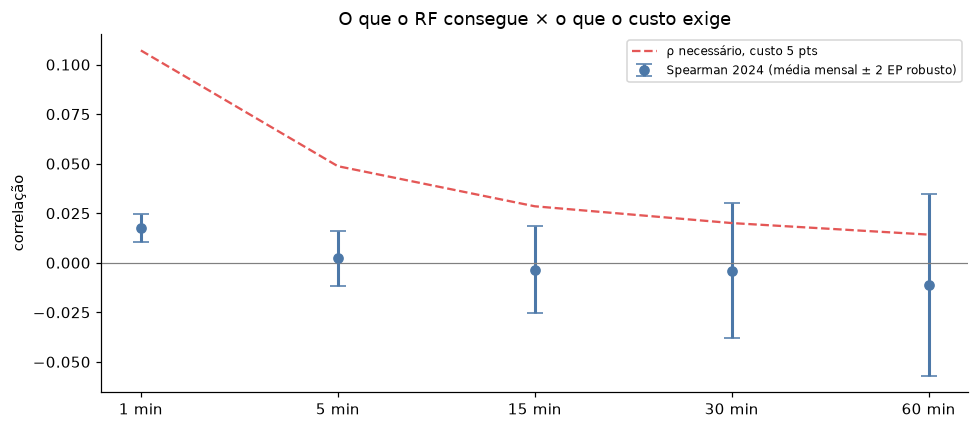

In [10]:
ep_rob = res["spearman_mensal_desvio"] / np.sqrt(12)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(x, res["spearman_mensal_medio"], yerr=2 * ep_rob, fmt="o", color="#4C78A8", capsize=5, lw=2,
            label="Spearman 2024 (média mensal ± 2 EP robusto)")
ax.plot(x, tab_mov["rho_nec_5pts"], "--", color="#E45756", label="ρ necessário, custo 5 pts")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x, [f"{k} min" for k in CANDLES]); ax.set_ylabel("correlação")
ax.set_title("O que o RF consegue × o que o custo exige")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4.2 Estabilidade mês a mês em 2024

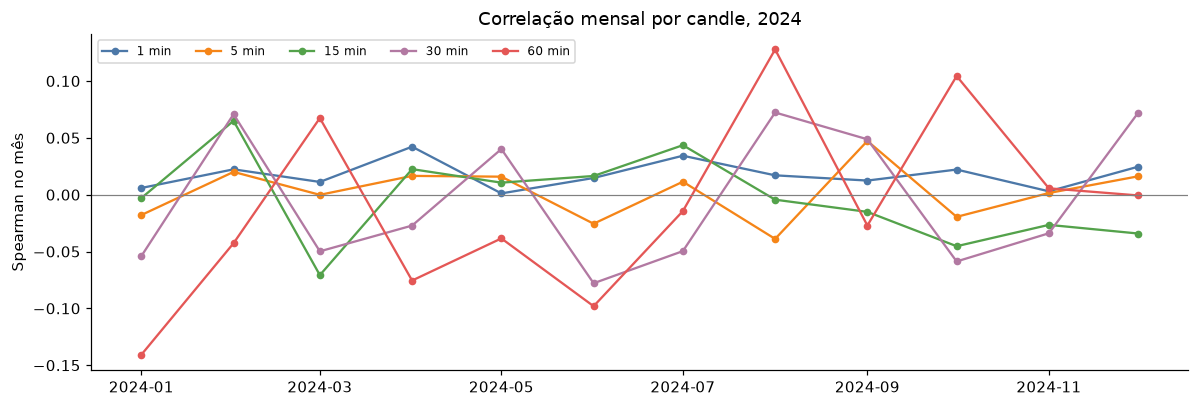

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for k in CANDLES:
    s = mensais[k]
    ax.plot(s.index.to_timestamp(), s.values, "o-", ms=4, color=CORES[k], label=f"{k} min")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Spearman no mês"); ax.set_title("Correlação mensal por candle, 2024")
ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

### 4.3 Variação seguinte por decil da previsão

Se a previsão tem sentido, as barras sobem do decil 1 (previsão mais negativa) para o 10 (mais positiva). As linhas vermelhas marcam ±5 pts: para operar com lucro, os decis extremos precisam passar delas.

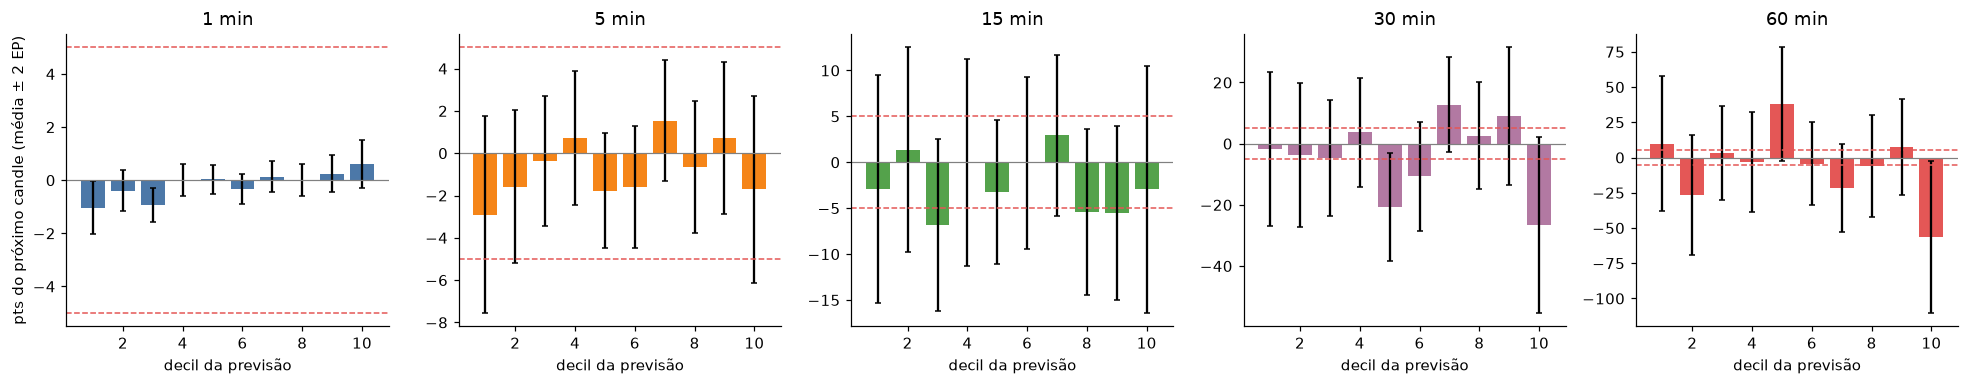

In [12]:
fig, axes = plt.subplots(1, len(CANDLES), figsize=(18, 3.6))
for ax, k in zip(axes, CANDLES):
    p = previsoes[k].copy()
    p["decil"] = pd.qcut(p["prev"].rank(method="first"), 10, labels=range(1, 11))
    g = p.groupby("decil", observed=True)["pts_prox"]
    media, ep = g.mean(), g.std(ddof=1) / np.sqrt(g.size())
    ax.bar(media.index.astype(int), media.values, yerr=2 * ep.values, color=CORES[k], capsize=2)
    ax.axhline(0, color="grey", lw=0.8)
    for c in (CUSTO_PTS, -CUSTO_PTS):
        ax.axhline(c, color="#E45756", ls="--", lw=1)
    ax.set_title(f"{k} min"); ax.set_xlabel("decil da previsão")
axes[0].set_ylabel("pts do próximo candle (média ± 2 EP)")
plt.tight_layout(); plt.show()

## 5. Robustez: o ranking muda com outra janela?

A janela é decidida no passo 3. Aqui só se confere se a escolha do candle depende da janela de 12 meses. As janelas de 6 e 24 meses pegam o buraco de jul–set/2023 (ver `n_treino_min`).

In [13]:
if RODAR_ROBUSTEZ:
    rob = [res.reset_index()[["candle_min", "janela_m", "spearman", "t_robusto", "theil_u"]]]
    for meses in JANELAS_ROBUSTEZ:
        for k in CANDLES:
            t1 = time.time()
            prev, ntr = walk_forward(bases[k], meses)
            linha, _ = painel(prev, k, meses, ntr)
            rob.append(pd.DataFrame([{c: linha[c] for c in ["candle_min", "janela_m", "spearman", "t_robusto", "theil_u"]}]))
            print(f"{k:>3} min × {meses:>2} m · ρ={linha['spearman']:+.4f}  t_rob={linha['t_robusto']:+.2f}  ({time.time() - t1:.0f}s)")
    rob = pd.concat(rob, ignore_index=True)
    tab_rob = rob.pivot(index="candle_min", columns="janela_m", values="spearman")
    tab_rank = tab_rob.rank(ascending=False).astype(int)
    print("\nSpearman 2024 por candle × janela:")
    display(tab_rob.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.03, vmax=0.03, axis=None))
    print("Posição do candle no ranking de cada janela (1 = melhor):")
    display(tab_rank)
else:
    rob = None
    print("Checagem de robustez desligada (RODAR_ROBUSTEZ = False).")

  1 min ×  6 m · ρ=+0.0120  t_rob=+3.59  (6s)


  5 min ×  6 m · ρ=+0.0136  t_rob=+1.99  (2s)


 15 min ×  6 m · ρ=-0.0051  t_rob=-0.66  (1s)


 30 min ×  6 m · ρ=+0.0150  t_rob=+0.80  (1s)


 60 min ×  6 m · ρ=-0.0092  t_rob=+0.13  (1s)


  1 min × 24 m · ρ=+0.0057  t_rob=+1.28  (28s)


... (3 outputs left out)

 60 min × 24 m · ρ=-0.0198  t_rob=-0.71  (1s)

Spearman 2024 por candle × janela:


janela_m,6,12,24
candle_min,,,
1,+0.0120,+0.0163,+0.0057
5,+0.0136,+0.0049,+0.0117
15,-0.0051,+0.0046,-0.0185
30,+0.0150,+0.0005,+0.0073
60,-0.0092,-0.0202,-0.0198


Posição do candle no ranking de cada janela (1 = melhor):


janela_m,6,12,24
candle_min,,,
1,3,1,3
5,2,2,1
15,4,3,4
30,1,4,2
60,5,5,5


## 6. Decisão

In [14]:
dec = res.copy()
dec["passa_theil"] = dec["theil_u"] <= TOL_THEIL
dec["sinal_significativo"] = (dec["t_robusto"] > 2) & (dec["spearman"] > 0)

candidatos = dec[dec["passa_theil"] & dec["sinal_significativo"]]
if len(candidatos):
    escolhido = candidatos.sort_values(["spearman", "spearman_mensal_desvio", "folga_sobre_custo"],
                                       ascending=[False, True, False]).index[0]
    situacao = "sinal significativo"
else:
    base_esc = dec[dec["passa_theil"]] if dec["passa_theil"].any() else dec
    escolhido = base_esc["spearman"].idxmax()
    situacao = "SEM sinal significativo (t robusto ≤ 2 em todos os candles)"

e = dec.loc[escolhido]
print(dec[["theil_u", "passa_theil", "spearman", "t_robusto", "meses_rho_pos", "sinal_significativo",
           "pts_brutos_op", "folga_sobre_custo"]].round(4).to_string())
print(f"\nCandle escolhido: {escolhido} min  ·  {situacao}")
print(f"  Theil U = {e['theil_u']:.5f} · Spearman = {e['spearman']:+.4f} · t robusto = {e['t_robusto']:+.2f} · "
      f"meses com ρ > 0 = {e['meses_rho_pos']}/12")
print(f"  Ganho bruto operando todo candle = {e['pts_brutos_op']:+.2f} ± {e['ep_pts']:.2f} pts "
      f"(ρ necessário p/ 5 pts = {tab_mov.loc[escolhido, 'rho_nec_5pts']:.3f})")

escolha = {"candle_min": int(escolhido), "situacao": situacao, "janela_m_usada": JANELA_MESES,
           "features": FEATURES, "rf_params": {k: v for k, v in RF_PARAMS.items() if k != "n_jobs"}}
(PASTA_RES / "passo1_escolha.json").write_text(json.dumps(escolha, indent=2, ensure_ascii=False))
tab_mov.to_csv(PASTA_RES / "passo1_movimento_custo.csv")
tab_rho1.to_csv(PASTA_RES / "passo1_rho1.csv")
res.to_csv(PASTA_RES / "passo1_modelo_2024.csv")
if rob is not None:
    rob.to_csv(PASTA_RES / "passo1_robustez_janelas.csv", index=False)
print(f"\nSalvo em {PASTA_RES}")

            theil_u  passa_theil  spearman  t_robusto  meses_rho_pos  sinal_significativo  pts_brutos_op  folga_sobre_custo
candle_min                                                                                                                 
1            1.0000         True    0.0163     4.9336             12                 True         0.3652            -4.6348
5            1.0005         True    0.0049     0.3212              7                False         0.2218            -4.7782
15           1.0025        False    0.0046    -0.3124              5                False        -0.7308            -5.7308
30           1.0051        False    0.0005    -0.2307              5                False        -2.0554            -7.0554
60           1.0132        False   -0.0202    -0.4810              4                False         0.1619            -4.8381

Candle escolhido: 1 min  ·  sinal significativo
  Theil U = 1.00003 · Spearman = +0.0163 · t robusto = +4.93 · meses com ρ > 0 = 12

## 7. Como ler e próximos passos

**Leitura do resultado**
- **Análise de dados (3.1 e 3.2):** se ρ₁ ficar dentro da faixa robusta em todos os candles e muito abaixo do ρ necessário, não há memória linear que pague o custo. Qualquer ganho do RF terá de vir de relações não lineares ou condicionais.
- **Modelo (4):** o candle escolhido é só o **melhor ponto de partida**. Um t robusto > 2 com ganho bruto bem abaixo do custo quer dizer que há sinal estatístico, mas não econômico, ainda.
- **Robustez (5):** se o candle escolhido muda de posição entre as janelas, a escolha é frágil. Vale confirmá-la no passo 6.

**Próximos passos do plano**
1. **Passo 2 — Features:** no candle escolhido, gerar ~15 candidatas e escolher 5–10 por Spearman, informação mútua, decis, estabilidade anual e importância por permutação.
2. **Passo 3 — Janela e retreino:** curva de envelhecimento do modelo e walk-forward com 3/6/12/24 meses × retreino mensal/trimestral/semestral.
3. **Passo 4 — Hiperparâmetros:** curva de nº de árvores e grade pequena de profundidade × % por folha × `max_features`.
4. **Passo 5 — Regras de compra e venda:** limiar pelos decis, lado, saída (TP/stop por volatilidade) e filtros de horário.
5. **Passo 6 — Confirmação, congelamento e validação** em 01/2025 → 03/2026.

**Limitações deste passo**
- Seleção feita só em 2024; repetir em 2023 aumentaria a confiança.
- O ρ necessário usa a aproximação normal; retornos têm caudas pesadas, então é uma ordem de grandeza.
- Features e hiperparâmetros básicos podem favorecer alguns candles; a confirmação do passo 6 cobre isso.

# Passo 2 — Escolha das features

**Pergunta:** quais informações o modelo deve enxergar, no candle escolhido no passo 1?

O passo segue três partes:

1. **Gerar as candidatas.** São ~20 features em 7 grupos, todas com informação só até t.
2. **Analisar os dados (até 31/12/2023, sem modelo).** Para cada candidata: relação com a direção do próximo retorno e estabilidade entre os meses e os anos. Também a informação mútua, que pega relações não lineares, e a relação com o tamanho do movimento. No fim, a retirada das redundantes.
3. **Confirmar com o modelo (2024).** Comparar conjuntos de features no mesmo RF do passo 1, medir a importância por permutação e retirar uma a uma.

| Fixo neste passo | Valor |
|---|---|
| Candle | o escolhido no passo 1 |
| Janela / re-treino | 12 meses, trimestral (revistos no passo 3) |
| RF | o mesmo do passo 1 (revisto no passo 4) |

**Critério de decisão** (definido antes de rodar):
1. **Pré-seleção pelos dados.** Uma candidata entra se tiver:
   - **direção:** |t mensal| ≥ 2 e o mesmo sinal da correlação em 2021, 2022 e 2023; **ou**
   - **informação:** informação mútua no quartil superior das candidatas.
2. **Redundância.** Entre pares com correlação > 0,8, fica a de maior |t mensal|.
3. **Confirmação.** Fica a feature com importância por permutação positiva em pelo menos 3 dos 4 trimestres de 2024. Se a retirada uma a uma estiver ligada, ela também precisa fazer falta quando é retirada.
4. **Escolha do conjunto final.** Entre os conjuntos testados, fica o de maior Spearman com t robusto > 2. Se outro conjunto estiver a até 1 erro-padrão dele, fica o que tiver menos features.

**Tempo no Colab:** cerca de 15 a 25 min com a retirada uma a uma (`RODAR_RETIRADA = True`) e 8 a 12 min sem ela.

## P2.0 Configuração

In [15]:
# ===== CONFIGURAÇÃO DO PASSO 2 =====
try:
    CANDLE_P2 = int(escolhido)                     # vem do passo 1
except NameError:
    CANDLE_P2 = json.loads((PASTA_RES / "passo1_escolha.json").read_text())["candle_min"]

JANELA_P2 = 12
ANOS_ESTAB = [2021, 2022, 2023]
LIMIAR_REDUND = 0.8
N_REPETICOES_PERM = 3
RODAR_RETIRADA = True
USAR_WDO = True
print(f"Candle do passo 2: {CANDLE_P2} min")


def localiza_wdo():
    nome = "WDO$N_M1.csv"
    for c in [ARQ_WIN.parent / nome, Path("/content") / nome]:
        if c.exists():
            return c
    if NO_COLAB:
        raiz = Path("/content/drive/MyDrive")
        if raiz.exists():
            achados = list(raiz.rglob(nome))
            if achados:
                return achados[0]
        try:
            from google.colab import files
            print("Selecione o arquivo WDO$N_M1.csv (cancele para seguir sem as features do dólar):")
            enviado = files.upload()
            if enviado:
                return Path("/content") / next(iter(enviado))
        except Exception as erro:
            print("Upload não feito:", erro)
    return None


wdo_m1 = None
if USAR_WDO:
    ARQ_WDO = localiza_wdo()
    if ARQ_WDO is None:
        print("WDO$N_M1.csv não encontrado: seguindo sem as features do dólar.")
    else:
        wdo_m1 = pd.read_csv(ARQ_WDO, sep="\t")
        wdo_m1.columns = [c.strip("<>").lower() for c in wdo_m1.columns]
        wdo_m1["dt"] = pd.to_datetime(wdo_m1["date"] + " " + wdo_m1["time"], format="%Y.%m.%d %H:%M:%S")
        wdo_m1 = wdo_m1.drop(columns=["date", "time", "spread"]).set_index("dt").sort_index()
        wdo_m1 = wdo_m1[~wdo_m1.index.duplicated()].between_time("09:00", "18:24")
        print(f"WDO: {len(wdo_m1):,} candles de 1 min · {wdo_m1.index.min().date()} -> {wdo_m1.index.max().date()}")

Candle do passo 2: 1 min


WDO: 712,996 candles de 1 min · 2020-09-17 -> 2026-04-01


## P2.1 Gerar as candidatas

Todas usam só informação disponível no fechamento do candle t. "c" = candles; no 1 min, 15c = 15 minutos.

| Grupo | Features | Ideia |
|---|---|---|
| Retornos recentes | `ret_0`, `ret_1`, `ret_2` | memória curta (momentum ou reversão) |
| Retornos acumulados | `ret_acum_5c`, `ret_acum_15c`, `ret_acum_60c` | tendência em escalas maiores, dentro do dia |
| Posição no dia | `ret_dia`, `pos_range_dia`, `hora` | quanto o dia já andou e onde o preço está na faixa do dia |
| Volatilidade | `vol_20`, `vol_60`, `vol_razao`, `rv_dia_ant`, `rv_media_5d` | regime de agitação; as duas últimas são os termos diário e semanal do HAR |
| Forma do candle | `range_hl`, `corpo`, `pos_fech_candle` | tamanho do candle e onde ele fechou dentro da própria faixa |
| Volume | `vol_rel` | volume ÷ média do mesmo horário nos 20 pregões anteriores |
| Abertura | `gap_abertura` | gap do dia sobre o fechamento anterior |
| Dólar (WDO) | `wdo_ret_0`, `wdo_ret_acum_15c` | o dólar no candle atual e nos últimos 15 |

"Minutos até o fechamento" ficou de fora: com o fechamento fixo às 18:25, ela é a mesma informação de `hora`.

In [16]:
def monta_base_p2(m1, minutos, wdo_m1=None):
    df = agrega_candles(m1, minutos)
    dia = df.index.normalize()
    lc = np.log(df["close"])
    ret = 100 * lc.groupby(dia).diff()
    r0 = ret.fillna(0.0)
    cs = r0.groupby(dia).cumsum()

    f = pd.DataFrame(index=df.index)
    # retornos
    f["ret_0"] = r0
    f["ret_1"] = ret.groupby(dia).shift(1).fillna(0.0)
    f["ret_2"] = ret.groupby(dia).shift(2).fillna(0.0)
    for k in (5, 15, 60):
        f[f"ret_acum_{k}c"] = cs - cs.groupby(dia).shift(k).fillna(0.0)
    # posição no dia
    f["ret_dia"] = 100 * (lc - np.log(df["open"].groupby(dia).transform("first")))
    hi, lo = df["high"].groupby(dia).cummax(), df["low"].groupby(dia).cummin()
    f["pos_range_dia"] = ((df["close"] - lo) / (hi - lo)).fillna(0.5)
    f["hora"] = df.index.hour + df.index.minute / 60
    # volatilidade
    f["vol_20"] = ret.rolling(20, min_periods=10).std()
    f["vol_60"] = ret.rolling(60, min_periods=20).std()
    f["vol_razao"] = f["vol_20"] / f["vol_60"]
    r1 = 100 * np.log(m1["close"]).groupby(m1.index.normalize()).diff()
    rv = np.sqrt((r1 ** 2).groupby(r1.index.normalize()).sum())          # vol realizada do dia
    f["rv_dia_ant"] = rv.shift(1).reindex(dia).values
    f["rv_media_5d"] = rv.shift(1).rolling(5, min_periods=3).mean().reindex(dia).values
    # forma do candle
    f["range_hl"] = 100 * np.log(df["high"] / df["low"])
    f["corpo"] = 100 * np.log(df["close"] / df["open"])
    f["pos_fech_candle"] = ((df["close"] - df["low"]) / (df["high"] - df["low"])).fillna(0.5)
    # volume relativo ao horário
    hhmm = df.index.hour * 100 + df.index.minute
    media_hor = df["vol"].groupby(hhmm).transform(lambda s: s.shift(1).rolling(20, min_periods=5).mean())
    f["vol_rel"] = df["vol"] / media_hor
    # gap de abertura
    gap = 100 * np.log(df["open"].groupby(dia).first() / df["close"].groupby(dia).last().shift(1))
    f["gap_abertura"] = gap.reindex(dia).fillna(0.0).values
    # dólar
    if wdo_m1 is not None:
        w = agrega_candles(wdo_m1, minutos)
        wd = w.index.normalize()
        wret = 100 * np.log(w["close"]).groupby(wd).diff()
        wcs = wret.fillna(0.0).groupby(wd).cumsum()
        f["wdo_ret_0"] = wret.reindex(df.index).fillna(0.0).values
        f["wdo_ret_acum_15c"] = (wcs - wcs.groupby(wd).shift(15).fillna(0.0)).reindex(df.index).fillna(0.0).values
    # alvo
    f["alvo"] = ret.groupby(dia).shift(-1)
    f["pts_prox"] = df["close"].groupby(dia).shift(-1) - df["close"]
    return f.replace([np.inf, -np.inf], np.nan).dropna()


t0 = time.time()
base2 = monta_base_p2(m1, CANDLE_P2, wdo_m1)
CAND = [c for c in base2.columns if c not in ("alvo", "pts_prox")]
ex2 = base2[base2.index <= FIM_EXPLORACAO]
print(f"{len(base2):,} linhas · {len(CAND)} candidatas · {len(ex2):,} linhas até 2023 ({time.time() - t0:.0f}s)")
base2[CAND].describe().T.round(4)

753,528 linhas · 21 candidatas · 368,682 linhas até 2023 (2s)


,count,mean,std,min,25%,50%,75%,max
ret_0,753528.0,0.0000,0.0458,-1.7943,-0.0207,0.0000,0.0206,1.2975
ret_1,753528.0,0.0000,0.0458,-1.7943,-0.0207,0.0000,0.0206,1.2975
ret_2,753528.0,0.0000,0.0458,-1.7943,-0.0206,0.0000,0.0205,1.2975
ret_acum_5c,753528.0,0.0000,0.1017,-1.7215,-0.0479,0.0000,0.0479,3.5463
ret_acum_15c,753528.0,0.0000,0.1747,-2.0735,-0.0831,0.0000,0.0828,4.3765
ret_acum_60c,753528.0,-0.0004,0.3462,-2.6346,-0.1733,0.0000,0.1706,4.3323
ret_dia,753528.0,-0.0058,0.8561,-4.7146,-0.5088,-0.0078,0.5013,5.4920
pos_range_dia,753528.0,0.5016,0.3032,0.0000,0.2238,0.4990,0.7834,1.0000
hora,753528.0,13.6332,2.6728,9.0000,11.3167,13.6333,15.9333,18.3833
vol_20,753528.0,0.0400,0.0228,0.0036,0.0243,0.0350,0.0500,0.6568


## P2.2 Análise de dados, até 2023

Para cada candidata:

| Medida | O que mostra |
|---|---|
| `spearman` | relação com a **direção** do próximo retorno, no período todo |
| `t_mensal` | média das correlações mensais ÷ erro-padrão entre meses; robusto à volatilidade em grupos |
| `anos_mesmo_sinal` | em quantos dos anos 2021, 2022 e 2023 a correlação teve o mesmo sinal do período todo |
| `mi` | informação mútua com o alvo, em decis, já descontado o acaso; pega qualquer relação, inclusive não linear (×1000 no gráfico) |
| `spearman_tamanho` | relação com o **tamanho** do próximo movimento, \|alvo\|; útil para o take profit e o stop do passo 5 |

In [17]:
from sklearn.metrics import mutual_info_score


def spearman_por_grupo(df, cols, chave):
    saida = {}
    for g, d in df.groupby(chave):
        r = d[cols + ["alvo"]].rank()
        saida[g] = r[cols].corrwith(r["alvo"])
    return pd.DataFrame(saida).T


t0 = time.time()
r_ex = ex2[CAND + ["alvo"]].rank()
sp_total = r_ex[CAND].corrwith(r_ex["alvo"])
sp_tam = r_ex[CAND].corrwith(ex2["alvo"].abs().rank())

mes = spearman_por_grupo(ex2, CAND, ex2.index.to_period("M"))
ex_anos = ex2[ex2.index.year.isin(ANOS_ESTAB)]
ano = spearman_por_grupo(ex_anos, CAND, ex_anos.index.year)

def mi_decis(x, y, n_bins=10, n_embaralhamentos=5, seed=SEED):
    # informação mútua em decis (empates ficam na mesma faixa), menos a média obtida
    # com o alvo embaralhado: o que sobra é informação além do acaso
    bx = pd.qcut(x, n_bins, labels=False, duplicates="drop")
    by = pd.qcut(y, n_bins, labels=False, duplicates="drop")
    real = mutual_info_score(bx, by)
    g = np.random.default_rng(seed)
    acaso = np.mean([mutual_info_score(bx, g.permutation(by)) for _ in range(n_embaralhamentos)])
    return real - acaso


mi = pd.Series({f: mi_decis(ex2[f], ex2["alvo"]) for f in CAND})

tab_feat = pd.DataFrame({
    "spearman": sp_total,
    "t_mensal": mes.mean() / (mes.std(ddof=1) / np.sqrt(len(mes))),
    "anos_mesmo_sinal": (np.sign(ano) == np.sign(sp_total)).sum().astype(int),
    "mi": mi,
    "spearman_tamanho": sp_tam,
})
for a in ANOS_ESTAB:
    tab_feat[f"sp_{a}"] = ano.loc[a]
tab_feat["abs_t"] = tab_feat["t_mensal"].abs()
tab_feat = tab_feat.sort_values("abs_t", ascending=False)
print(f"{len(mes)} meses na análise ({time.time() - t0:.0f}s)")

tab_feat.drop(columns="abs_t").style.format({
    "spearman": "{:+.4f}", "t_mensal": "{:+.2f}", "mi": "{:.5f}", "spearman_tamanho": "{:+.3f}",
    **{f"sp_{a}": "{:+.4f}" for a in ANOS_ESTAB},
}).background_gradient(subset=["t_mensal"], cmap="RdBu", vmin=-6, vmax=6) \
  .background_gradient(subset=["mi"], cmap="Blues") \
  .background_gradient(subset=["spearman_tamanho"], cmap="Greens", vmin=0, vmax=0.5)

36 meses na análise (14s)


,spearman,t_mensal,anos_mesmo_sinal,mi,spearman_tamanho,sp_2021,sp_2022,sp_2023
ret_acum_15c,-0.0161,-8.90,3,0.01764,-0.015,-0.0152,-0.0147,-0.0213
pos_range_dia,-0.0085,-7.11,3,0.00246,-0.056,-0.0101,-0.0053,-0.0118
ret_dia,-0.0059,-5.63,3,0.00182,-0.049,-0.0120,-0.0028,-0.0044
ret_acum_60c,-0.0119,-5.26,3,0.01300,-0.029,-0.0114,-0.0107,-0.0149
wdo_ret_acum_15c,+0.0085,+4.55,3,0.00806,+0.011,+0.0097,+0.0064,+0.0141
ret_acum_5c,-0.0106,-4.52,3,0.01758,-0.011,-0.0042,-0.0147,-0.0161
vol_razao,-0.0051,-2.73,3,0.00440,+0.088,-0.0074,-0.0050,-0.0049
ret_1,-0.0079,-2.60,3,0.01369,-0.005,-0.0108,-0.0056,-0.0067
ret_2,-0.0064,-2.05,3,0.01315,-0.006,-0.0038,-0.0115,-0.0046
rv_media_5d,-0.0001,+1.89,1,0.01966,+0.189,-0.0042,+0.0033,+0.0008


### Direção × informação × tamanho

- **Painel da esquerda:** força da relação com a direção. As barras escuras têm o mesmo sinal nos 3 anos; as linhas tracejadas marcam |t| = 2.
- **Painel do meio:** informação mútua. A linha marca o quartil superior, que é o corte de entrada.
- **Painel da direita:** relação com o tamanho do movimento. Features de volatilidade quase não dizem a direção, mas dizem muito sobre o tamanho.

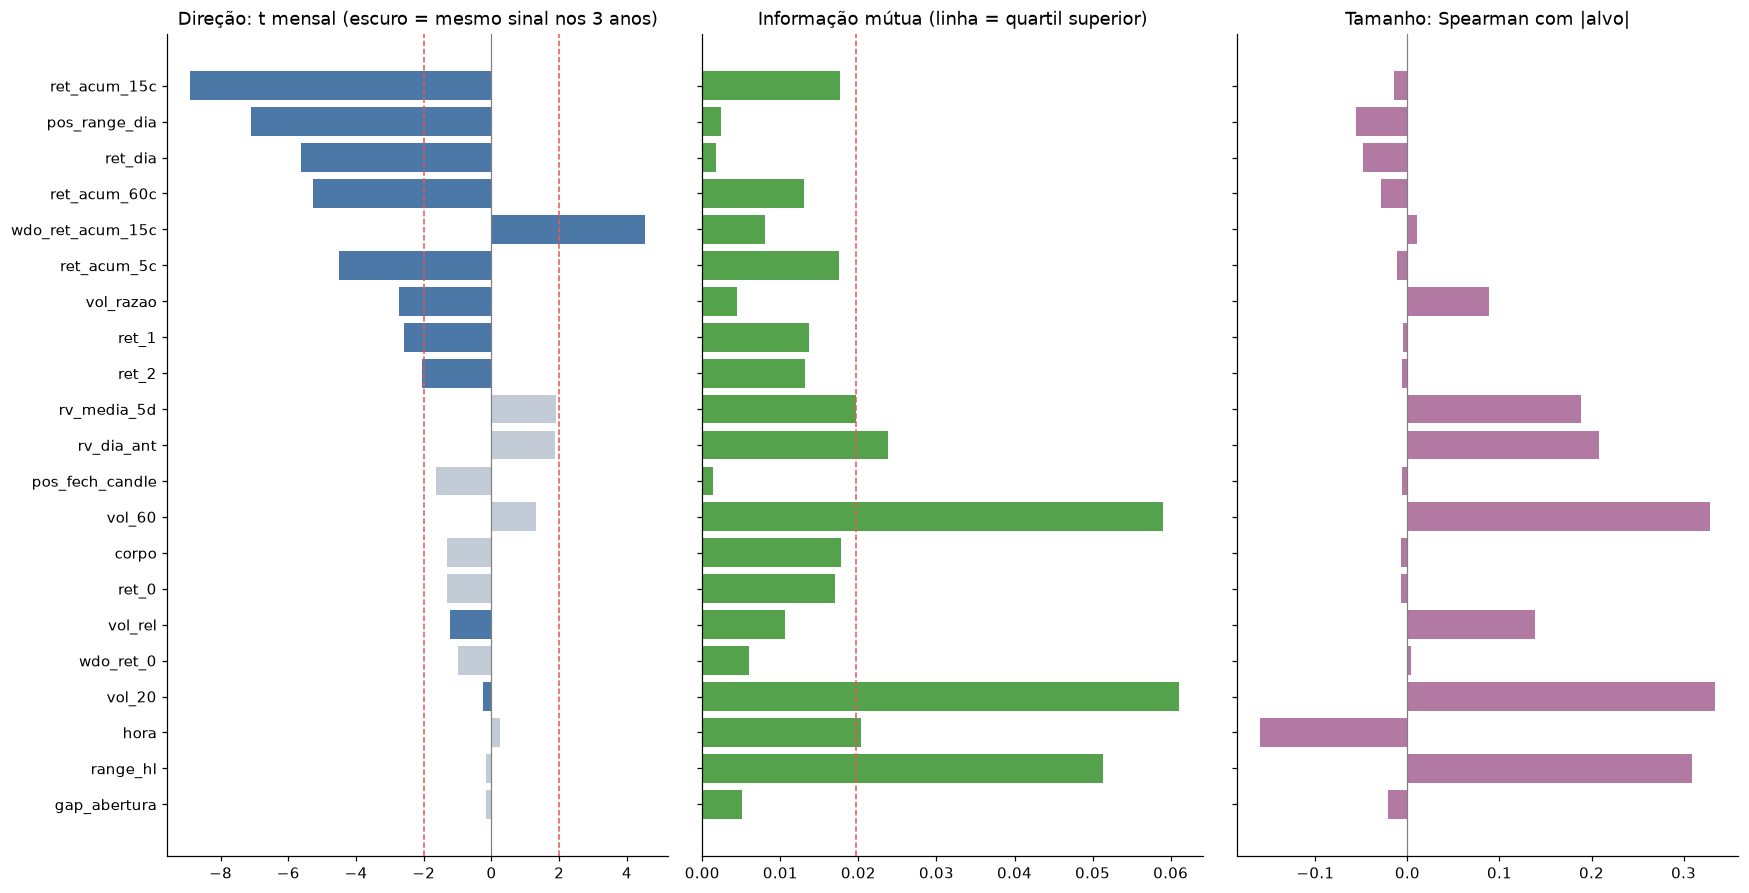

In [18]:
ordem = tab_feat.index[::-1]
y = np.arange(len(ordem))
estavel = tab_feat.loc[ordem, "anos_mesmo_sinal"] == len(ANOS_ESTAB)
mi_corte = tab_feat["mi"].quantile(0.75)

fig, axes = plt.subplots(1, 3, figsize=(16, 0.32 * len(ordem) + 1.5), sharey=True)
axes[0].barh(y, tab_feat.loc[ordem, "t_mensal"], color=np.where(estavel, "#4C78A8", "#c3ccd6"))
for v in (-2, 2):
    axes[0].axvline(v, color="#E45756", ls="--", lw=1)
axes[0].axvline(0, color="grey", lw=0.8)
axes[0].set_title("Direção: t mensal (escuro = mesmo sinal nos 3 anos)")
axes[1].barh(y, tab_feat.loc[ordem, "mi"], color="#54A24B")
axes[1].axvline(mi_corte, color="#E45756", ls="--", lw=1)
axes[1].set_title("Informação mútua (linha = quartil superior)")
axes[2].barh(y, tab_feat.loc[ordem, "spearman_tamanho"], color="#B279A2")
axes[2].axvline(0, color="grey", lw=0.8)
axes[2].set_title("Tamanho: Spearman com |alvo|")
axes[0].set_yticks(y, ordem)
plt.tight_layout(); plt.show()

### Variação seguinte por decil, ano a ano (8 candidatas de maior |t mensal|)

Uma relação útil aparece **igual nos três anos**: as linhas andam juntas e inclinadas. Linhas que se cruzam ou trocam de inclinação indicam ruído ou mudança de regime.

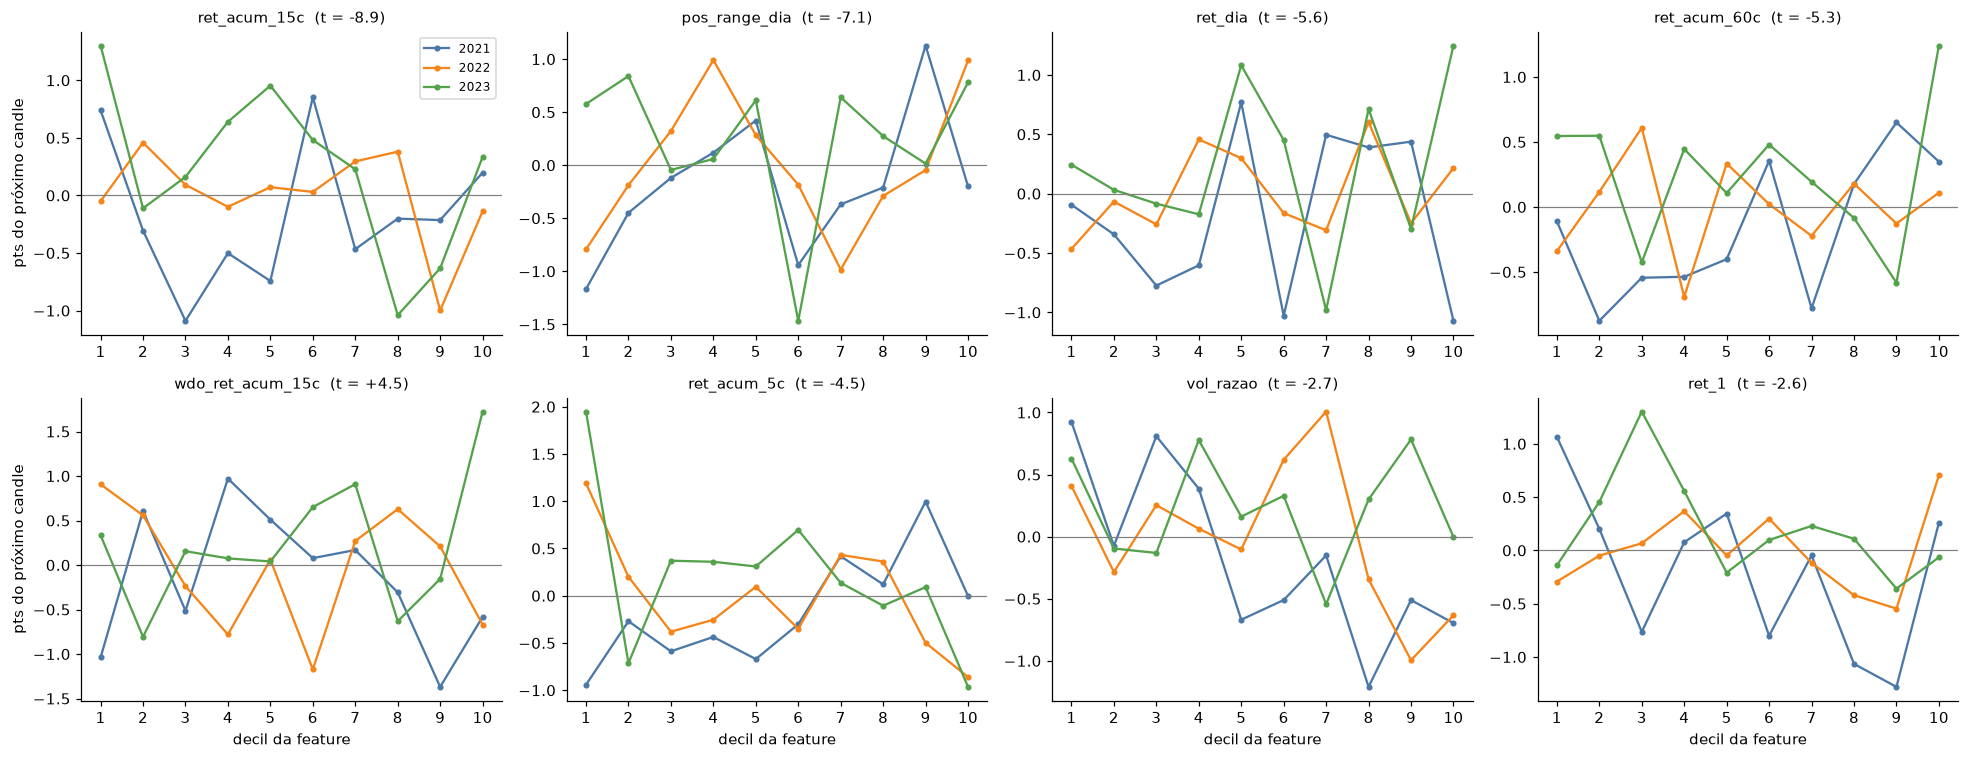

In [19]:
top8 = tab_feat.index[:8]
cores_ano = {2021: "#4C78A8", 2022: "#F58518", 2023: "#54A24B"}
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=False)
for ax, f in zip(axes.ravel(), top8):
    d = ex_anos[[f, "pts_prox"]].copy()
    d["decil"] = pd.qcut(d[f].rank(method="first"), 10, labels=range(1, 11))
    g = d.groupby([d.index.year, "decil"], observed=True)["pts_prox"].mean().unstack(0)
    for a in ANOS_ESTAB:
        ax.plot(g.index.astype(int), g[a], "o-", ms=3, color=cores_ano[a], label=str(a))
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{f}  (t = {tab_feat.loc[f, 't_mensal']:+.1f})", fontsize=10)
    ax.set_xticks(range(1, 11))
axes[0, 0].set_ylabel("pts do próximo candle"); axes[1, 0].set_ylabel("pts do próximo candle")
axes[0, 0].legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("decil da feature")
plt.tight_layout(); plt.show()

### Redundância entre candidatas

Na matriz de correlação de Spearman entre as candidatas, só os valores com |ρ| ≥ 0,5 aparecem escritos. Pares acima de 0,8 carregam praticamente a mesma informação.

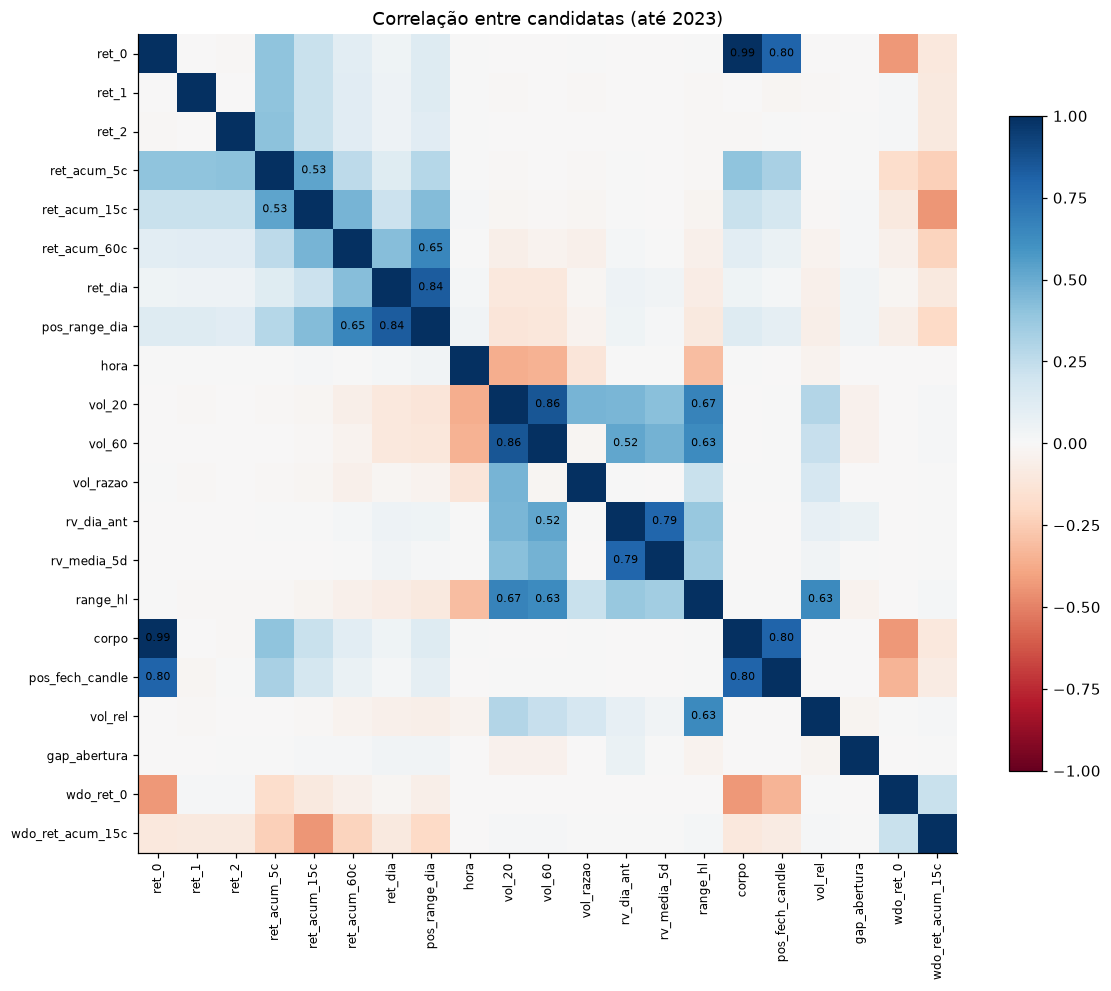

Pares redundantes (|ρ| > 0,8): [('ret_0', 'corpo', np.float64(0.9949576379259333)), ('ret_dia', 'pos_range_dia', np.float64(0.8352895467758447)), ('vol_20', 'vol_60', np.float64(0.8563702722472084))]


In [20]:
corr = ex2[CAND].sample(min(100_000, len(ex2)), random_state=SEED).corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(CAND)), CAND, rotation=90, fontsize=8)
ax.set_yticks(range(len(CAND)), CAND, fontsize=8)
for i in range(len(CAND)):
    for j in range(len(CAND)):
        if i != j and abs(corr.values[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlação entre candidatas (até 2023)")
plt.tight_layout(); plt.show()

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(CAND) for b in CAND[i + 1:] if abs(corr.loc[a, b]) > LIMIAR_REDUND]
print("Pares redundantes (|ρ| > 0,8):", pares if pares else "nenhum")

### Pré-seleção pelos dados

In [21]:
tab_feat["direcao"] = (tab_feat["abs_t"] >= 2) & (tab_feat["anos_mesmo_sinal"] == len(ANOS_ESTAB))
tab_feat["informacao"] = tab_feat["mi"] >= mi_corte
tab_feat["candidata"] = tab_feat["direcao"] | tab_feat["informacao"]

PRE, motivo = [], {}
for f in tab_feat.sort_values(["candidata", "abs_t", "mi"], ascending=False).index:
    if not tab_feat.loc[f, "candidata"]:
        motivo[f] = "sem relação estável e sem informação"
        continue
    par = [m for m in PRE if abs(corr.loc[f, m]) > LIMIAR_REDUND]
    if par:
        motivo[f] = f"redundante com {par[0]}"
    else:
        PRE.append(f)
        motivo[f] = "direção" if tab_feat.loc[f, "direcao"] else "informação"
        if tab_feat.loc[f, "direcao"] and tab_feat.loc[f, "informacao"]:
            motivo[f] = "direção + informação"
if not PRE:
    PRE = list(FEATURES)
    print("Nenhuma candidata passou: usando as features básicas do passo 1.")

tab_feat["resultado_analise"] = pd.Series(motivo)
print(f"Pré-selecionadas ({len(PRE)}): {PRE}\n")
print(tab_feat[["t_mensal", "anos_mesmo_sinal", "mi", "resultado_analise"]].round(4).to_string())

Pré-selecionadas (13): ['ret_acum_15c', 'pos_range_dia', 'ret_acum_60c', 'wdo_ret_acum_15c', 'ret_acum_5c', 'vol_razao', 'ret_1', 'ret_2', 'rv_media_5d', 'rv_dia_ant', 'vol_60', 'hora', 'range_hl']

                  t_mensal  anos_mesmo_sinal      mi                     resultado_analise
ret_acum_15c       -8.8978                 3  0.0176                               direção
pos_range_dia      -7.1121                 3  0.0025                               direção
ret_dia            -5.6281                 3  0.0018          redundante com pos_range_dia
ret_acum_60c       -5.2649                 3  0.0130                               direção
wdo_ret_acum_15c    4.5481                 3  0.0081                               direção
ret_acum_5c        -4.5164                 3  0.0176                               direção
vol_razao          -2.7253                 3  0.0044                               direção
ret_1              -2.5972                 3  0.0137                     

## P2.3 Confirmação com o modelo, em 2024

O mesmo RF e o mesmo walk-forward do passo 1 (12 meses, re-treino trimestral), mudando só as features:

| Conjunto | Features |
|---|---|
| básico | as 5 do passo 1 |
| todas | todas as candidatas |
| pré-selecionadas | as que passaram na análise de dados |

Depois:
- **Importância por permutação:** em cada trimestre, embaralha uma feature no período de teste e mede quanto o Spearman cai. Queda positiva significa que a feature ajuda.
- **Retirada uma a uma (opcional):** re-treina sem cada feature e mede a queda do Spearman.

In [22]:
def walk_forward_feats(base, meses, feats, guardar=False):
    prevs, n_tr, modelos = [], [], []
    for q in TRIMESTRES:
        ini, fim = q.start_time, q.end_time
        tr = base[(base.index >= ini - pd.DateOffset(months=meses)) & (base.index < ini)]
        te = base[(base.index >= ini) & (base.index <= fim)]
        rf = RandomForestRegressor(**RF_PARAMS).fit(tr[feats], tr["alvo"])
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[feats]),
                                   "pts_prox": te["pts_prox"]}, index=te.index))
        n_tr.append(len(tr))
        if guardar:
            modelos.append((rf, te))
    return pd.concat(prevs), min(n_tr), modelos


def avalia_conjunto(nome, feats, guardar=False):
    t1 = time.time()
    prev, ntr, modelos = walk_forward_feats(base2, JANELA_P2, feats, guardar)
    linha, mensal = painel(prev, CANDLE_P2, JANELA_P2, ntr)
    linha.update(conjunto=nome, n_features=len(feats), features=", ".join(feats))
    print(f"{nome:<28} {len(feats):>2} feats · ρ={linha['spearman']:+.4f}  t_rob={linha['t_robusto']:+.2f}  "
          f"U={linha['theil_u']:.5f}  bruto={linha['pts_brutos_op']:+.2f} pts  ({time.time() - t1:.0f}s)")
    return linha, mensal, modelos


comparacao, mensais_p2 = [], {}
for nome, feats in [("básico (passo 1)", FEATURES), ("todas as candidatas", CAND)]:
    linha, mensal, _ = avalia_conjunto(nome, feats)
    comparacao.append(linha); mensais_p2[nome] = mensal
linha, mensal, modelos_pre = avalia_conjunto("pré-selecionadas (análise)", PRE, guardar=True)
comparacao.append(linha); mensais_p2["pré-selecionadas (análise)"] = mensal

básico (passo 1)              5 feats · ρ=+0.0163  t_rob=+4.93  U=1.00003  bruto=+0.37 pts  (11s)


todas as candidatas          21 feats · ρ=+0.0222  t_rob=+5.34  U=0.99997  bruto=+0.43 pts  (41s)


pré-selecionadas (análise)   13 feats · ρ=+0.0093  t_rob=+4.16  U=1.00009  bruto=+0.11 pts  (26s)


Permutação: 13s


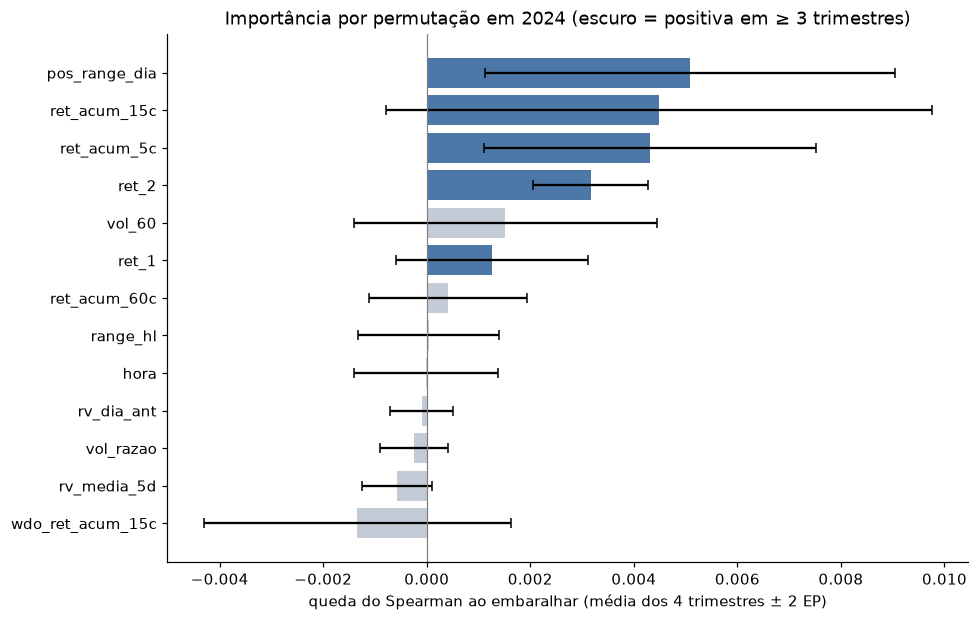

,queda_media,ep,trimestres_positivos
wdo_ret_acum_15c,-0.00134,0.00148,2
rv_media_5d,-0.00057,0.00034,0
vol_razao,-0.00025,0.00033,2
rv_dia_ant,-0.00010,0.00030,2
hora,-0.00001,0.00070,1
range_hl,0.00004,0.00068,2
ret_acum_60c,0.00041,0.00076,2
ret_1,0.00126,0.00093,3
vol_60,0.00152,0.00146,2
ret_2,0.00317,0.00056,4


In [23]:
# Importância por permutação: queda do Spearman ao embaralhar cada feature no teste
rng = np.random.default_rng(SEED)
t0 = time.time()
quedas = {f: [] for f in PRE}
for rf, te in modelos_pre:
    X, yv = te[PRE].copy(), te["alvo"].values
    rho_base = spearmanr(rf.predict(X), yv)[0]
    for f in PRE:
        original = X[f].values.copy()
        q = []
        for _ in range(N_REPETICOES_PERM):
            X[f] = rng.permutation(original)
            q.append(rho_base - spearmanr(rf.predict(X), yv)[0])
        X[f] = original
        quedas[f].append(np.mean(q))

imp = pd.DataFrame({
    "queda_media": {f: np.mean(v) for f, v in quedas.items()},
    "ep": {f: np.std(v, ddof=1) / np.sqrt(len(v)) for f, v in quedas.items()},
    "trimestres_positivos": {f: int(np.sum(np.array(v) > 0)) for f, v in quedas.items()},
}).sort_values("queda_media")
print(f"Permutação: {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(9, 0.35 * len(imp) + 1.2))
cores = np.where(imp["trimestres_positivos"] >= 3, "#4C78A8", "#c3ccd6")
ax.barh(imp.index, imp["queda_media"], xerr=2 * imp["ep"], color=cores, capsize=3)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("queda do Spearman ao embaralhar (média dos 4 trimestres ± 2 EP)")
ax.set_title("Importância por permutação em 2024 (escuro = positiva em ≥ 3 trimestres)")
plt.tight_layout(); plt.show()
imp.round(5)

In [24]:
CONFIRMADAS = [f for f in PRE if imp.loc[f, "queda_media"] > 0 and imp.loc[f, "trimestres_positivos"] >= 3]
if not CONFIRMADAS:
    CONFIRMADAS = [f for f in PRE if imp.loc[f, "queda_media"] > 0] or list(PRE)
print(f"Confirmadas pela permutação ({len(CONFIRMADAS)}): {CONFIRMADAS}")

linha, mensal, _ = avalia_conjunto("confirmadas (permutação)", CONFIRMADAS)
comparacao.append(linha); mensais_p2["confirmadas (permutação)"] = mensal
rho_conf = linha["spearman_mensal_medio"]

retirada = None
FINAIS = list(CONFIRMADAS)
if RODAR_RETIRADA and len(CONFIRMADAS) > 1:
    print("\nRetirada uma a uma:")
    linhas = []
    for f in CONFIRMADAS:
        resto = [c for c in CONFIRMADAS if c != f]
        prev, ntr, _ = walk_forward_feats(base2, JANELA_P2, resto)
        l, _ = painel(prev, CANDLE_P2, JANELA_P2, ntr)
        linhas.append({"feature": f, "spearman_sem": l["spearman_mensal_medio"],
                       "queda_ao_retirar": rho_conf - l["spearman_mensal_medio"]})
        print(f"  sem {f:<18} ρ={l['spearman_mensal_medio']:+.4f}  queda={rho_conf - l['spearman_mensal_medio']:+.4f}")
    retirada = pd.DataFrame(linhas).set_index("feature").sort_values("queda_ao_retirar", ascending=False)
    FINAIS = [f for f in CONFIRMADAS if retirada.loc[f, "queda_ao_retirar"] > 0] or list(CONFIRMADAS)
    if FINAIS != CONFIRMADAS:
        linha, mensal, _ = avalia_conjunto("finais (retirada)", FINAIS)
        comparacao.append(linha); mensais_p2["finais (retirada)"] = mensal

Confirmadas pela permutação (5): ['ret_acum_15c', 'pos_range_dia', 'ret_acum_5c', 'ret_1', 'ret_2']


confirmadas (permutação)      5 feats · ρ=+0.0138  t_rob=+8.19  U=1.00001  bruto=+0.08 pts  (13s)

Retirada uma a uma:


  sem ret_acum_15c       ρ=+0.0129  queda=+0.0024


  sem pos_range_dia      ρ=+0.0141  queda=+0.0011


  sem ret_acum_5c        ρ=+0.0136  queda=+0.0017


  sem ret_1              ρ=+0.0169  queda=-0.0016


  sem ret_2              ρ=+0.0133  queda=+0.0020


finais (retirada)             4 feats · ρ=+0.0152  t_rob=+7.32  U=0.99998  bruto=+0.33 pts  (11s)


## P2.4 Comparação dos conjuntos e decisão

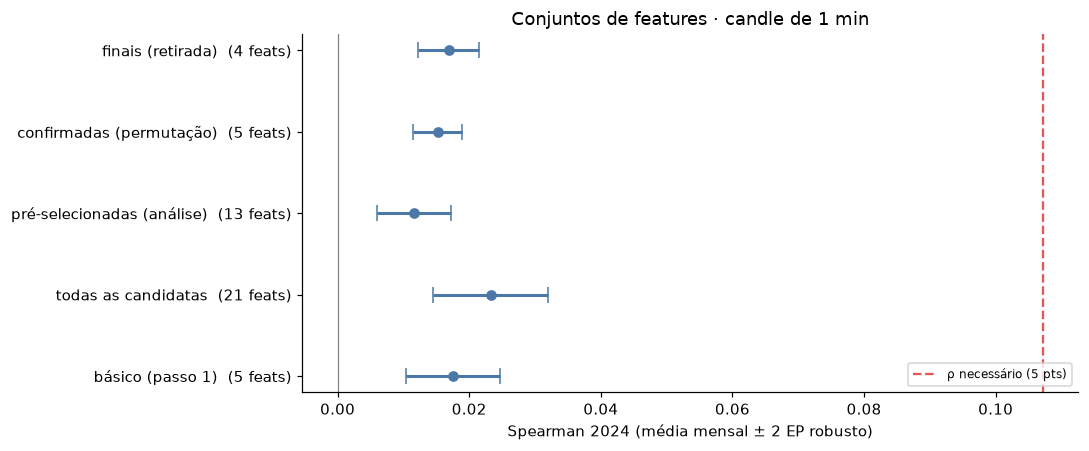

,n_features,theil_u,spearman,spearman_mensal_medio,t_robusto,meses_rho_pos,acerto_dir,desvio_prev_sobre_real,pts_brutos_op,ep_pts,folga_sobre_custo
conjunto,,,,,,,,,,,
básico (passo 1),5,1.00003,+0.0163,+0.0176,+4.93,12,50.9%,0.023,+0.37,0.11,-4.63
todas as candidatas,21,0.99997,+0.0222,+0.0233,+5.34,12,51.3%,0.023,+0.43,0.11,-4.57
pré-selecionadas (análise),13,1.00009,+0.0093,+0.0116,+4.16,12,50.6%,0.015,+0.11,0.11,-4.89
confirmadas (permutação),5,1.00001,+0.0138,+0.0152,+8.19,12,50.5%,0.019,+0.08,0.11,-4.92
finais (retirada),4,0.99998,+0.0152,+0.0169,+7.32,12,50.7%,0.020,+0.33,0.11,-4.67


In [25]:
comp = pd.DataFrame(comparacao).set_index("conjunto")
comp["ep_robusto"] = comp["spearman_mensal_desvio"] / np.sqrt(12)

fig, ax = plt.subplots(figsize=(10, 0.6 * len(comp) + 1.2))
yy = np.arange(len(comp))
ax.errorbar(comp["spearman_mensal_medio"], yy, xerr=2 * comp["ep_robusto"], fmt="o", color="#4C78A8", capsize=5, lw=2)
ax.axvline(0, color="grey", lw=0.8)
ax.axvline(tab_mov.loc[CANDLE_P2, "rho_nec_5pts"], color="#E45756", ls="--", label="ρ necessário (5 pts)")
ax.set_yticks(yy, [f"{n}  ({k} feats)" for n, k in zip(comp.index, comp["n_features"])])
ax.set_xlabel("Spearman 2024 (média mensal ± 2 EP robusto)")
ax.set_title(f"Conjuntos de features · candle de {CANDLE_P2} min")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

comp[["n_features", "theil_u", "spearman", "spearman_mensal_medio", "t_robusto", "meses_rho_pos",
      "acerto_dir", "desvio_prev_sobre_real", "pts_brutos_op", "ep_pts", "folga_sobre_custo"]].style.format({
    "theil_u": "{:.5f}", "spearman": "{:+.4f}", "spearman_mensal_medio": "{:+.4f}", "t_robusto": "{:+.2f}",
    "acerto_dir": "{:.1%}", "desvio_prev_sobre_real": "{:.3f}", "pts_brutos_op": "{:+.2f}", "ep_pts": "{:.2f}",
    "folga_sobre_custo": "{:+.2f}"})

In [26]:
# Regra: entre os conjuntos com t robusto > 2 e Theil U <= tolerância, o de maior Spearman;
# se outro estiver a até 1 EP dele, fica o que tem menos features.
eleg = comp[(comp["t_robusto"] > 2) & (comp["theil_u"] <= TOL_THEIL)]
if len(eleg):
    melhor = eleg["spearman_mensal_medio"].idxmax()
    piso = eleg.loc[melhor, "spearman_mensal_medio"] - eleg.loc[melhor, "ep_robusto"]
    empatados = eleg[eleg["spearman_mensal_medio"] >= piso]
    conjunto_final = empatados.sort_values(["n_features", "spearman_mensal_medio"], ascending=[True, False]).index[0]
    situacao_p2 = "sinal significativo"
else:
    conjunto_final = comp["spearman_mensal_medio"].idxmax()
    situacao_p2 = "SEM conjunto com t robusto > 2"

FEATURES_P2 = comp.loc[conjunto_final, "features"].split(", ")
e2 = comp.loc[conjunto_final]
print(f"Conjunto escolhido: {conjunto_final}  ·  {situacao_p2}")
print(f"  Features ({len(FEATURES_P2)}): {FEATURES_P2}")
print(f"  Spearman 2024 = {e2['spearman_mensal_medio']:+.4f} ± {e2['ep_robusto']:.4f} · t robusto = {e2['t_robusto']:+.2f} · "
      f"meses ρ>0 = {e2['meses_rho_pos']}/12 · Theil U = {e2['theil_u']:.5f}")
print(f"  Ganho bruto operando todo candle = {e2['pts_brutos_op']:+.2f} ± {e2['ep_pts']:.2f} pts "
      f"(passo 1: {comp.loc['básico (passo 1)', 'pts_brutos_op']:+.2f})")

saida_p2 = {"candle_min": CANDLE_P2, "conjunto": conjunto_final, "situacao": situacao_p2, "features": FEATURES_P2,
            "pre_selecionadas": PRE, "confirmadas_permutacao": CONFIRMADAS}
(PASTA_RES / "passo2_features.json").write_text(json.dumps(saida_p2, indent=2, ensure_ascii=False))
tab_feat.to_csv(PASTA_RES / "passo2_analise_candidatas.csv")
imp.to_csv(PASTA_RES / "passo2_importancia_permutacao.csv")
comp.to_csv(PASTA_RES / "passo2_comparacao_conjuntos.csv")
if retirada is not None:
    retirada.to_csv(PASTA_RES / "passo2_retirada.csv")
print(f"\nSalvo em {PASTA_RES}")

Conjunto escolhido: todas as candidatas  ·  sinal significativo
  Features (21): ['ret_0', 'ret_1', 'ret_2', 'ret_acum_5c', 'ret_acum_15c', 'ret_acum_60c', 'ret_dia', 'pos_range_dia', 'hora', 'vol_20', 'vol_60', 'vol_razao', 'rv_dia_ant', 'rv_media_5d', 'range_hl', 'corpo', 'pos_fech_candle', 'vol_rel', 'gap_abertura', 'wdo_ret_0', 'wdo_ret_acum_15c']
  Spearman 2024 = +0.0233 ± 0.0044 · t robusto = +5.34 · meses ρ>0 = 12/12 · Theil U = 0.99997
  Ganho bruto operando todo candle = +0.43 ± 0.11 pts (passo 1: +0.37)

Salvo em C:\Users\anabi\AppData\Local\Temp\claude\7443c3ed6403f415\e018eed5-a243-4290-aadd-86ab9ea34b5d\scratchpad\rerun\resultados


## P2.5 Como ler e próximos passos

**Leitura do resultado**
- **Análise de dados.** Candidatas com |t mensal| alto e o mesmo sinal nos 3 anos são as que têm relação de direção. As de volatilidade aparecem com informação mútua e relação com o tamanho, mas não com a direção. Para o RF, elas servem como **contexto**: dizem quando as outras relações valem mais.
- **Modelo.** Se o conjunto escolhido melhorar o Spearman sem chegar perto do ρ necessário, o ganho é estatístico, mas ainda não econômico. A etapa de regras (passo 5) tenta operar só nos candles de previsão mais forte.
- **Relação com o tamanho.** Ela não entra no critério deste passo, mas já indica quais features usar no take profit e no stop do passo 5.

**Próximos passos do plano**
1. **Passo 3 — Janela e retreino:** com `FEATURES_P2`, a curva de envelhecimento do modelo e o walk-forward com 3/6/12/24 meses × retreino mensal/trimestral/semestral.
2. **Passo 4 — Hiperparâmetros:** curva de nº de árvores e grade de profundidade × % por folha × `max_features`.
3. **Passo 5 — Regras de compra e venda.**
4. **Passo 6 — Confirmação, congelamento e validação.**

**Limitações deste passo**
- A importância por permutação subestima features correlacionadas entre si. Por isso a redundância é removida antes.
- A informação mútua é calculada em decis, descontando o valor obtido com o alvo embaralhado. O estimador por vizinhos do scikit-learn foi descartado porque infla features que se repetem o dia inteiro (gap, vol do dia anterior).
- O quartil superior de informação mútua é um corte relativo: sempre deixa entrar ~25% das candidatas, mesmo que todas tenham pouca informação. A confirmação com o modelo filtra isso.

# Passo 3 — Janela de treino e periodicidade de retreino

**Pergunta:** quanto passado o modelo deve ver e de quanto em quanto tempo deve ser refeito?

| Opção | Valores |
|---|---|
| Janela de treino | 3, 6, 12, 24 meses ou expansiva (todo o histórico disponível) |
| Retreino | mensal, trimestral, semestral |

O passo tem duas partes:

1. **Análise de dados (até 2023):**
   - **as relações mudam com o tempo?** Correlação mês a mês das features mais fortes com o alvo, junto com o nível de preço e a volatilidade. Se as relações e os regimes mudam rápido, janelas longas misturam períodos diferentes;
   - **curva de envelhecimento:** treinar uma vez e medir a correlação no 1º, 2º, ..., 12º mês depois do treino. Se ela não cai, retreinar pouco basta.
2. **Modelo (2024):**
   - **estágio A:** as 5 janelas com retreino trimestral;
   - **estágio B:** retreino mensal e semestral nas 2 melhores janelas do estágio A.

| Fixo neste passo | Valor |
|---|---|
| Candle e features | os escolhidos nos passos 1 e 2 |
| RF | profundidade 5, 1% do treino por folha, como antes, com **100 árvores e no máximo 50 mil linhas sorteadas por árvore** |

O teto de linhas deixa o tempo de cada treino igual para qualquer janela; sem ele, a janela expansiva levaria ~10× mais. Ele afeta só a variância do modelo: as 100 árvores, juntas, ainda cobrem a janela toda. O número de árvores é revisto no passo 4.

**Critério de decisão** (definido antes de rodar):
1. Entre as combinações com t robusto > 2 e Theil U ≤ 1,001, a de maior Spearman (média mensal de 2024).
2. Se outras estiverem a até 1 erro-padrão dela, fica a de **retreino menos frequente** (mais barata de operar). Persistindo o empate, a de janela mais curta.
3. A curva de envelhecimento entra como apoio: se ela for plana, reforça o retreino menos frequente.

**Tempo no Colab:** cerca de 20 a 35 min (≈ 53 treinos). Aqui, num computador de 12 núcleos, levou cerca de 6 min.

## P3.0 Configuração

In [27]:
# ===== CONFIGURAÇÃO DO PASSO 3 =====
try:
    FEATURES_P3 = list(FEATURES_P2)
    CANDLE_P3 = int(CANDLE_P2)
except NameError:
    _p2 = json.loads((PASTA_RES / "passo2_features.json").read_text())
    FEATURES_P3, CANDLE_P3 = _p2["features"], _p2["candle_min"]
    base2 = monta_base_p2(m1, CANDLE_P3, wdo_m1)   # precisa das células do passo 2 de definição

JANELAS_P3 = [3, 6, 12, 24, "expansiva"]
RETREINOS_P3 = ["mensal", "trimestral", "semestral"]
LIM_LINHAS_ARVORE = 50_000
RF_P3 = dict(n_estimators=100, max_depth=5, min_samples_leaf=0.01, max_features=1.0,
             n_jobs=-1, random_state=SEED)
ORIGENS_ENVELHECIMENTO = ["2022-01-01", "2022-04-01", "2022-07-01", "2022-10-01", "2023-01-01"]

INICIO_DADOS = base2.index.min()
print(f"Candle {CANDLE_P3} min · {len(FEATURES_P3)} features · dados desde {INICIO_DADOS.date()}")


def treina_rf(tr, feats):
    ms = min(0.5, LIM_LINHAS_ARVORE / len(tr))
    return RandomForestRegressor(**RF_P3, max_samples=ms).fit(tr[feats], tr["alvo"])


def inicio_treino(ini, janela):
    return INICIO_DADOS if janela == "expansiva" else ini - pd.DateOffset(months=janela)

Candle 1 min · 21 features · dados desde 2020-10-22


## P3.1 Análise de dados: as relações e os regimes mudam?

- **Painel de cima:** correlação de Spearman, mês a mês, das 6 features de maior |t mensal| do passo 2 com o alvo. A linha grossa é a média móvel de 6 meses. Uma relação útil fica do mesmo lado do zero o tempo todo.
- **Painel de baixo:** nível de preço e volatilidade mensal (desvio dos retornos de 1 candle). Mudanças grandes de regime pedem janelas mais curtas.

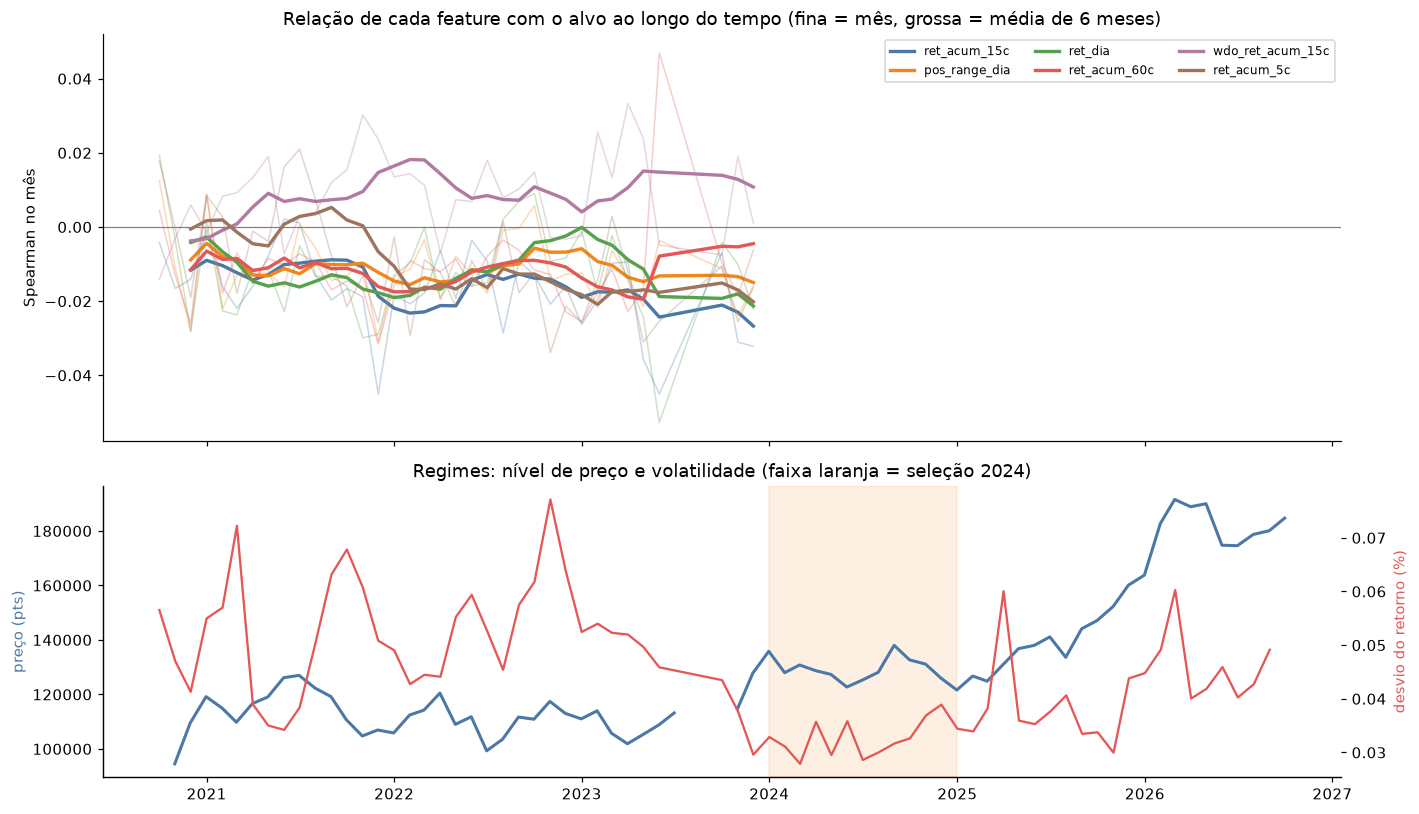

autocorr_mensal: correlação da relação de um mês com a do mês seguinte (alta = relação persistente)


,spearman_medio,meses_mesmo_sinal_%,autocorr_mensal
ret_acum_15c,-0.017,94.444,0.197
pos_range_dia,-0.011,88.889,-0.163
ret_dia,-0.012,86.111,0.172
ret_acum_60c,-0.011,91.667,-0.027
wdo_ret_acum_15c,0.009,72.222,0.291
ret_acum_5c,-0.011,77.778,0.353


In [28]:
top6 = [f for f in tab_feat.index if f in FEATURES_P3][:6]
ex3 = base2[base2.index <= FIM_EXPLORACAO]
mes_top = spearman_por_grupo(ex3, top6, ex3.index.to_period("M"))
mes_top.index = mes_top.index.to_timestamp()

cores6 = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#9D755D"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
for f, c in zip(top6, cores6):
    axes[0].plot(mes_top.index, mes_top[f], color=c, alpha=0.30, lw=1)
    axes[0].plot(mes_top.index, mes_top[f].rolling(6, min_periods=3).mean(), color=c, lw=2.2, label=f)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_ylabel("Spearman no mês"); axes[0].legend(ncol=3, fontsize=8)
axes[0].set_title("Relação de cada feature com o alvo ao longo do tempo (fina = mês, grossa = média de 6 meses)")

preco = m1["close"].resample("ME").last()
vol_mes = base2["alvo"].groupby(base2.index.to_period("M")).std()
vol_mes.index = vol_mes.index.to_timestamp()
ax2 = axes[1]
ax2.plot(preco.index, preco.values, color="#4C78A8", lw=2, label="preço de fechamento (pts)")
ax2.set_ylabel("preço (pts)", color="#4C78A8")
ax3 = ax2.twinx()
ax3.plot(vol_mes.index, vol_mes.values, color="#E45756", lw=1.5, label="volatilidade mensal (%)")
ax3.set_ylabel("desvio do retorno (%)", color="#E45756")
ax2.axvspan(pd.Timestamp(f"{ANO_SELECAO}-01-01"), pd.Timestamp(f"{ANO_SELECAO}-12-31"), color="#F58518", alpha=0.12)
ax2.set_title("Regimes: nível de preço e volatilidade (faixa laranja = seleção 2024)")
plt.tight_layout(); plt.show()

estab = pd.DataFrame({
    "spearman_medio": mes_top.mean(),
    "meses_mesmo_sinal_%": [100 * (np.sign(mes_top[f]) == np.sign(mes_top[f].mean())).mean() for f in top6],
    "autocorr_mensal": [mes_top[f].autocorr(1) for f in top6],
}, index=top6)
print("autocorr_mensal: correlação da relação de um mês com a do mês seguinte (alta = relação persistente)")
estab.round(3)

## P3.2 Curva de envelhecimento do modelo (até 2023)

Em cada uma de 5 datas de origem (jan/2022 a jan/2023), o modelo é treinado com os 12 meses anteriores e **não é refeito**. Em seguida, mede-se o Spearman em cada mês depois da origem, até dez/2023. Os meses do buraco de 2023 ficam de fora.

- **Curva plana:** o que o modelo aprendeu continua valendo, e retreinar pouco basta.
- **Curva caindo:** o modelo envelhece, e é preciso retreinar com mais frequência.

Envelhecimento: 5 treinos (34s)


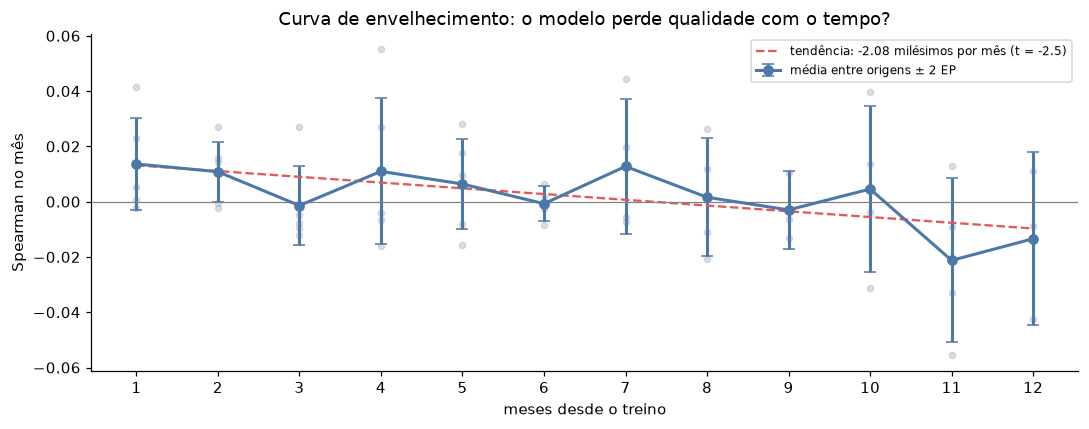

Leitura: a correlação CAI com a idade do modelo: favorece retreino mais frequente


,mean,std,count,ep
idade_meses,,,,
1,0.0136,0.0185,5,0.0083
2,0.0108,0.0122,5,0.0055
3,-0.0014,0.0161,5,0.0072
4,0.0110,0.0295,5,0.0132
5,0.0064,0.0180,5,0.0081
6,-0.0007,0.0064,4,0.0032
7,0.0128,0.0244,4,0.0122
8,0.0016,0.0213,4,0.0107
9,-0.0030,0.0121,3,0.0070


In [29]:
t0 = time.time()
linhas = []
for o in pd.to_datetime(ORIGENS_ENVELHECIMENTO):
    tr = base2[(base2.index >= o - pd.DateOffset(months=12)) & (base2.index < o)]
    te = base2[(base2.index >= o) & (base2.index <= FIM_EXPLORACAO)]
    rf = treina_rf(tr, FEATURES_P3)
    p = pd.Series(rf.predict(te[FEATURES_P3]), index=te.index)
    for per, d in te.groupby(te.index.to_period("M")):
        if len(d) < 2000:
            continue
        idade = (per - o.to_period("M")).n + 1
        linhas.append({"origem": o.date(), "idade_meses": idade, "spearman": spearmanr(p.loc[d.index], d["alvo"])[0]})
env = pd.DataFrame(linhas)
env = env[env["idade_meses"] <= 12]
print(f"Envelhecimento: {len(ORIGENS_ENVELHECIMENTO)} treinos ({time.time() - t0:.0f}s)")

curva = env.groupby("idade_meses")["spearman"].agg(["mean", "std", "count"])
curva["ep"] = curva["std"] / np.sqrt(curva["count"])

# inclinação (queda por mês) por mínimos quadrados, com erro-padrão aproximado
xv, yv = env["idade_meses"].values, env["spearman"].values
inc, intercepto = np.polyfit(xv, yv, 1)
resid = yv - (inc * xv + intercepto)
ep_inc = np.sqrt(np.sum(resid ** 2) / (len(xv) - 2) / np.sum((xv - xv.mean()) ** 2))
t_inc = inc / ep_inc

fig, ax = plt.subplots(figsize=(10, 4))
for o, d in env.groupby("origem"):
    ax.plot(d["idade_meses"], d["spearman"], "o", ms=4, alpha=0.35, color="#9aa5b1")
ax.errorbar(curva.index, curva["mean"], yerr=2 * curva["ep"], fmt="o-", color="#4C78A8", lw=2, capsize=4,
            label="média entre origens ± 2 EP")
xs = np.arange(1, 13)
ax.plot(xs, inc * xs + intercepto, "--", color="#E45756",
        label=f"tendência: {inc * 1000:+.2f} milésimos por mês (t = {t_inc:+.1f})")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(xs); ax.set_xlabel("meses desde o treino"); ax.set_ylabel("Spearman no mês")
ax.set_title("Curva de envelhecimento: o modelo perde qualidade com o tempo?")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

if t_inc < -2:
    leitura_env = "a correlação CAI com a idade do modelo: favorece retreino mais frequente"
else:
    leitura_env = "sem queda significativa com a idade do modelo: retreino menos frequente é suficiente"
print("Leitura:", leitura_env)
curva.round(4)

## P3.3 Modelo em 2024: janelas × retreino

Mesmo walk-forward dos passos anteriores, agora com a janela e a frequência variando:

- **mensal:** 12 treinos no ano, cada um prevê o mês seguinte;
- **trimestral:** 4 treinos;
- **semestral:** 2 treinos.

In [30]:
def periodos_retreino(retreino, ano=ANO_SELECAO):
    if retreino == "semestral":
        cortes = pd.to_datetime([f"{ano}-01-01", f"{ano}-07-01", f"{ano + 1}-01-01"])
    else:
        freq = "M" if retreino == "mensal" else "Q"
        pr = pd.period_range(f"{ano}-01", f"{ano}-12", freq=freq)
        cortes = [p.start_time for p in pr] + [(pr[-1] + 1).start_time]
    return list(zip(cortes[:-1], cortes[1:]))


def walk_forward_p3(janela, retreino, feats=None):
    feats = feats or FEATURES_P3
    prevs, n_tr = [], []
    for ini, fim in periodos_retreino(retreino):
        tr = base2[(base2.index >= inicio_treino(ini, janela)) & (base2.index < ini)]
        te = base2[(base2.index >= ini) & (base2.index < fim)]
        rf = treina_rf(tr, feats)
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[feats]),
                                   "pts_prox": te["pts_prox"]}, index=te.index))
        n_tr.append(len(tr))
    return pd.concat(prevs), min(n_tr)


res_p3, mensais_p3 = [], {}

def roda_combinacao(janela, retreino):
    t1 = time.time()
    prev, ntr = walk_forward_p3(janela, retreino)
    linha, mensal = painel(prev, CANDLE_P3, janela, ntr)
    linha.update(janela=str(janela), retreino=retreino, n_treinos=len(periodos_retreino(retreino)))
    res_p3.append(linha); mensais_p3[(str(janela), retreino)] = mensal
    print(f"janela {str(janela):>9} · {retreino:<10} ρ={linha['spearman_mensal_medio']:+.4f}  "
          f"t_rob={linha['t_robusto']:+.2f}  U={linha['theil_u']:.5f}  n_treino_min={ntr:,}  ({time.time() - t1:.0f}s)")


print("Estágio A: janelas com retreino trimestral")
for j in JANELAS_P3:
    roda_combinacao(j, "trimestral")

estagio_a = pd.DataFrame(res_p3)
top2 = estagio_a.sort_values("spearman_mensal_medio", ascending=False)["janela"].head(2).tolist()
print(f"\nEstágio B: retreino mensal e semestral nas janelas {top2}")
for j in top2:
    jj = j if j == "expansiva" else int(j)
    for r in [r for r in RETREINOS_P3 if r != "trimestral"]:
        roda_combinacao(jj, r)

Estágio A: janelas com retreino trimestral


janela         3 · trimestral ρ=+0.0115  t_rob=+2.31  U=1.00062  n_treino_min=27,320  (10s)


janela         6 · trimestral ρ=+0.0173  t_rob=+3.35  U=1.00016  n_treino_min=27,320  (15s)


janela        12 · trimestral ρ=+0.0242  t_rob=+5.98  U=0.99996  n_treino_min=83,902  (24s)


janela        24 · trimestral ρ=+0.0103  t_rob=+2.29  U=0.99990  n_treino_min=215,290  (32s)


janela expansiva · trimestral ρ=-0.0064  t_rob=-1.20  U=1.00009  n_treino_min=368,682  (29s)

Estágio B: retreino mensal e semestral nas janelas ['12', '6']


janela        12 · mensal     ρ=+0.0241  t_rob=+5.15  U=0.99991  n_treino_min=83,902  (63s)


janela        12 · semestral  ρ=+0.0225  t_rob=+4.79  U=0.99999  n_treino_min=84,573  (10s)


janela         6 · mensal     ρ=+0.0167  t_rob=+3.58  U=1.00015  n_treino_min=27,320  (39s)


janela         6 · semestral  ρ=+0.0154  t_rob=+3.20  U=1.00022  n_treino_min=27,320  (5s)


### Resultado: Spearman por janela e retreino

As células em branco são as combinações que não foram rodadas (estágio B só nas 2 melhores janelas). Os números mostram o Spearman médio mensal e, abaixo, o t robusto.

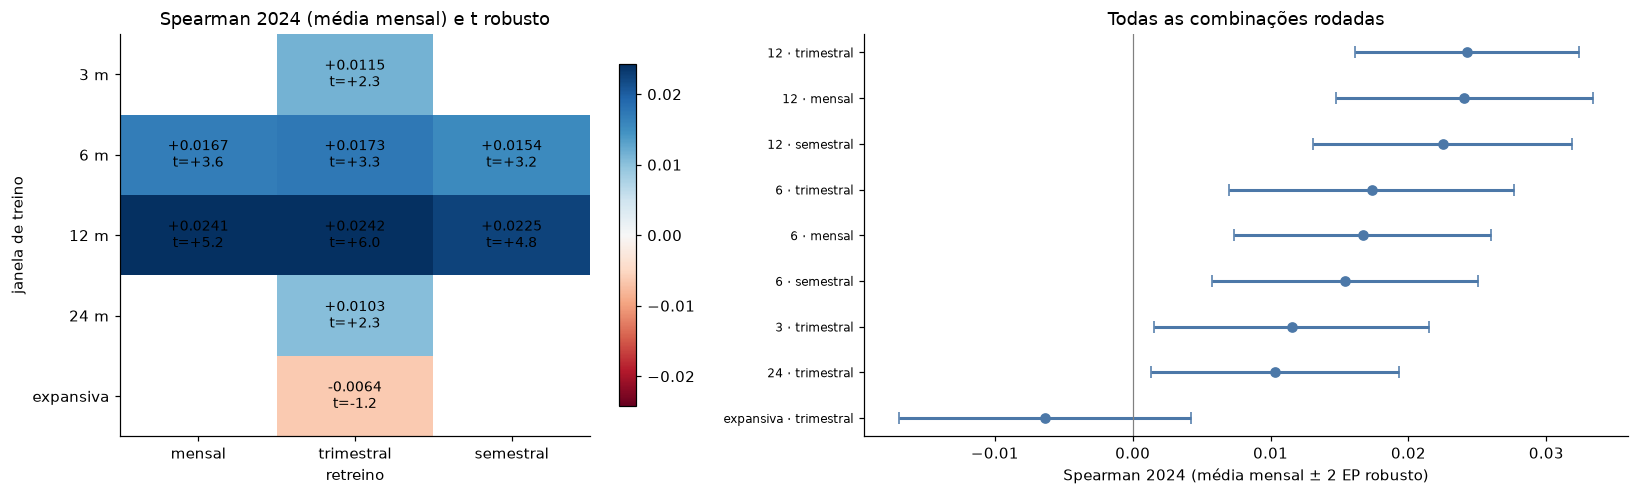

In [31]:
r3 = pd.DataFrame(res_p3)
r3["ep_robusto"] = r3["spearman_mensal_desvio"] / np.sqrt(12)
ordem_j = [str(j) for j in JANELAS_P3]
piv = r3.pivot(index="janela", columns="retreino", values="spearman_mensal_medio").reindex(index=ordem_j, columns=RETREINOS_P3)
pivt = r3.pivot(index="janela", columns="retreino", values="t_robusto").reindex(index=ordem_j, columns=RETREINOS_P3)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
v = piv.values.astype(float)
a = np.nanmax(np.abs(v))
im = axes[0].imshow(v, cmap="RdBu", vmin=-a, vmax=a, aspect="auto")
axes[0].set_xticks(range(len(RETREINOS_P3)), RETREINOS_P3)
axes[0].set_yticks(range(len(ordem_j)), [f"{j} m" if j != "expansiva" else j for j in ordem_j])
for i in range(v.shape[0]):
    for k in range(v.shape[1]):
        if np.isfinite(v[i, k]):
            axes[0].text(k, i, f"{v[i, k]:+.4f}\nt={pivt.values[i, k]:+.1f}", ha="center", va="center", fontsize=9)
axes[0].set_xlabel("retreino"); axes[0].set_ylabel("janela de treino")
axes[0].set_title("Spearman 2024 (média mensal) e t robusto")
plt.colorbar(im, ax=axes[0], shrink=0.85)

r3s = r3.sort_values("spearman_mensal_medio")
yy = np.arange(len(r3s))
axes[1].errorbar(r3s["spearman_mensal_medio"], yy, xerr=2 * r3s["ep_robusto"], fmt="o", color="#4C78A8", capsize=4, lw=2)
axes[1].axvline(0, color="grey", lw=0.8)
axes[1].set_yticks(yy, [f"{j} · {r}" for j, r in zip(r3s["janela"], r3s["retreino"])], fontsize=8)
axes[1].set_xlabel("Spearman 2024 (média mensal ± 2 EP robusto)")
axes[1].set_title("Todas as combinações rodadas")
plt.tight_layout(); plt.show()

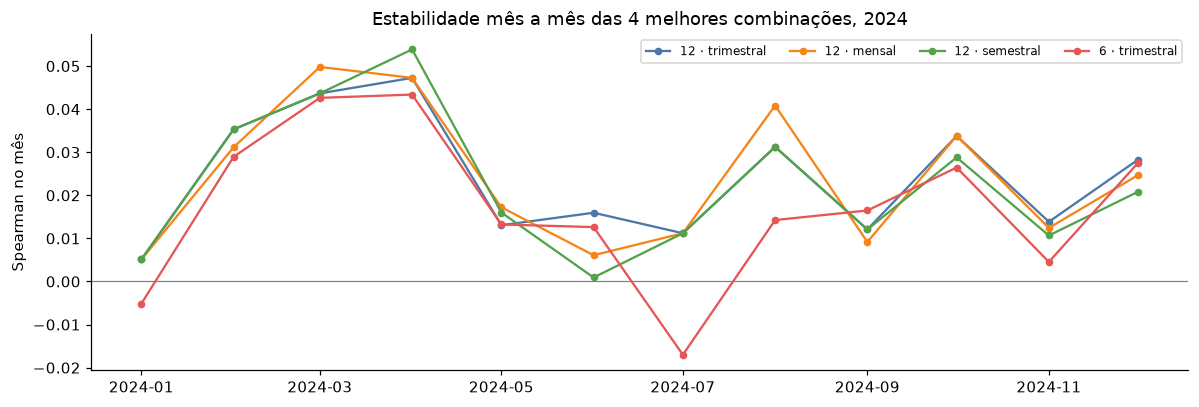

In [32]:
fig, ax = plt.subplots(figsize=(11, 3.8))
melhores = r3.sort_values("spearman_mensal_medio", ascending=False).head(4)
for (_, l), c in zip(melhores.iterrows(), ["#4C78A8", "#F58518", "#54A24B", "#E45756"]):
    s = mensais_p3[(l["janela"], l["retreino"])]
    ax.plot(s.index.to_timestamp(), s.values, "o-", ms=4, color=c, label=f"{l['janela']} · {l['retreino']}")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Spearman no mês"); ax.set_title("Estabilidade mês a mês das 4 melhores combinações, 2024")
ax.legend(fontsize=8, ncol=4); plt.tight_layout(); plt.show()

## P3.4 Decisão

In [33]:
freq_ordem = {"semestral": 0, "trimestral": 1, "mensal": 2}      # menos frequente primeiro
jan_ordem = {"3": 0, "6": 1, "12": 2, "24": 3, "expansiva": 4}    # mais curta primeiro
r3["ordem_freq"] = r3["retreino"].map(freq_ordem)
r3["ordem_jan"] = r3["janela"].map(jan_ordem)

eleg3 = r3[(r3["t_robusto"] > 2) & (r3["theil_u"] <= TOL_THEIL)]
if len(eleg3):
    melhor3 = eleg3.loc[eleg3["spearman_mensal_medio"].idxmax()]
    piso3 = melhor3["spearman_mensal_medio"] - melhor3["ep_robusto"]
    emp3 = eleg3[eleg3["spearman_mensal_medio"] >= piso3]
    final3 = emp3.sort_values(["ordem_freq", "ordem_jan", "spearman_mensal_medio"], ascending=[True, True, False]).iloc[0]
    situacao_p3 = "sinal significativo"
else:
    final3 = r3.loc[r3["spearman_mensal_medio"].idxmax()]
    situacao_p3 = "SEM combinação com t robusto > 2"

JANELA_P3 = final3["janela"] if final3["janela"] == "expansiva" else int(final3["janela"])
RETREINO_P3 = final3["retreino"]

print(r3.sort_values("spearman_mensal_medio", ascending=False)[
    ["janela", "retreino", "n_treinos", "n_treino_min", "theil_u", "spearman_mensal_medio", "ep_robusto",
     "t_robusto", "meses_rho_pos", "pts_brutos_op"]].round(5).to_string(index=False))
print(f"\nMelhor combinação: janela {melhor3['janela'] if len(eleg3) else final3['janela']} · "
      f"{melhor3['retreino'] if len(eleg3) else final3['retreino']}")
print(f"Escolhida (regra: a até 1 EP, retreino menos frequente): janela {JANELA_P3} · retreino {RETREINO_P3}  ·  {situacao_p3}")
print(f"  Spearman 2024 = {final3['spearman_mensal_medio']:+.4f} ± {final3['ep_robusto']:.4f} · "
      f"t robusto = {final3['t_robusto']:+.2f} · meses ρ>0 = {final3['meses_rho_pos']}/12")
print(f"  Curva de envelhecimento: {leitura_env}")

saida_p3 = {"candle_min": CANDLE_P3, "features": FEATURES_P3, "janela": JANELA_P3, "retreino": RETREINO_P3,
            "situacao": situacao_p3, "envelhecimento": leitura_env,
            "inclinacao_envelhecimento_por_mes": float(inc), "t_inclinacao": float(t_inc),
            "rf_passo3": {**{k: v for k, v in RF_P3.items() if k != "n_jobs"}, "lim_linhas_arvore": LIM_LINHAS_ARVORE}}
(PASTA_RES / "passo3_janela_retreino.json").write_text(json.dumps(saida_p3, indent=2, ensure_ascii=False))
r3.to_csv(PASTA_RES / "passo3_janela_retreino.csv", index=False)
env.to_csv(PASTA_RES / "passo3_envelhecimento.csv", index=False)
print(f"\nSalvo em {PASTA_RES}")

   janela   retreino  n_treinos  n_treino_min  theil_u  spearman_mensal_medio  ep_robusto  t_robusto  meses_rho_pos  pts_brutos_op
       12 trimestral          4         83902  0.99996                0.02423     0.00406    5.97514             12        0.51489
       12     mensal         12         83902  0.99991                0.02406     0.00467    5.15321             12        0.56061
       12  semestral          2         84573  0.99999                0.02247     0.00469    4.79470             12        0.44193
        6 trimestral          4         27320  1.00016                0.01733     0.00518    3.34642             10        0.24596
        6     mensal         12         27320  1.00015                0.01668     0.00466    3.57955             10        0.19005
        6  semestral          2         27320  1.00022                0.01542     0.00482    3.19581             10        0.30881
        3 trimestral          4         27320  1.00062                0.01152     0

## P3.5 Como ler e próximos passos

**Leitura do resultado**
- **Relações ao longo do tempo (P3.1).** Se as features principais ficam do mesmo lado do zero quase todos os meses, o sinal é estrutural, e janelas longas não atrapalham. Se mudam de sinal, janelas curtas se adaptam melhor.
- **Envelhecimento (P3.2).** Uma curva plana quer dizer que o modelo não "vence" rápido. É o argumento de dados para um retreino menos frequente.
- **Grade (P3.3).** Diferenças de Spearman menores que 1 erro-padrão são empate. Por isso a regra prefere a opção mais barata de operar.

**Próximos passos do plano**
1. **Passo 4 — Hiperparâmetros:**
   - curva de nº de árvores (100 → 500);
   - grade de profundidade (3, 5, 8) × % do treino por folha (0,5%, 1%, 2%, 5%) × `max_features`;
   - revisar o teto de linhas por árvore.
2. **Passo 5 — Regras de compra e venda:** limiar pelos decis da previsão, lado, saída (TP/stop pela volatilidade) e filtros de horário.
3. **Passo 6 — Confirmação, congelamento e validação** em 01/2025 → 03/2026.

**Limitações deste passo**
- A curva de envelhecimento usa só 5 origens e o buraco de 2023. É indicativa, não precisa.
- O estágio B só testou outras frequências nas 2 melhores janelas do estágio A.
- O RF deste passo (100 árvores, teto de 50 mil linhas por árvore) é mais leve que o dos passos 1 e 2. Os números não são comparáveis um a um com os anteriores, só entre as opções deste passo.

# Passo 4 — Hiperparâmetros do Random Forest

**Pergunta:** qual a complexidade certa do RF para um sinal tão fraco?

| Hiperparâmetro | O que controla | Valores |
|---|---|---|
| Nº de árvores | só a estabilidade da média; mais árvores não sobreajustam | curva 25 → 400 |
| Profundidade máxima | quantas interações entre features cada árvore aprende | 3, 5, 8 |
| % do treino por folha | quantos candles formam cada previsão; folha grande = previsão mais suave | 0,5%, 1%, 2%, 5% |
| `max_features` | quantas features cada divisão pode considerar (diversidade entre árvores) | `sqrt`, 0,5, 1,0 |

O passo tem quatro partes:

1. **Análise de dados (até 2023).** Para que a média de uma folha seja distinguível de zero, ela precisa de $n \ge 4\sigma^2/\delta^2$ candles. Aqui σ é o desvio do retorno e δ o efeito que se quer detectar, medido nos decis das features mais fortes. Isso dá o **tamanho mínimo de folha** e, por consequência, a **profundidade máxima útil**, antes de treinar qualquer modelo.
2. **Curva do nº de árvores**, com a configuração atual: a partir de quantas árvores o resultado para de mudar.
3. **Estágio A:** grade de profundidade × % por folha, com `max_features = 1,0`.
4. **Estágio B:** `max_features` = `sqrt` e 0,5 nas 2 melhores combinações do estágio A.
5. **Estágio C (automático):** se a melhor configuração cair na borda da grade, a grade é estendida nessa direção: folhas de 10% e 20% e/ou uma profundidade a menos. Esse estágio foi incluído depois da primeira execução, que pôs o ótimo exatamente na borda (folha de 5%, profundidade 3).

Para cada configuração, além do Spearman de validação, mede-se o **Spearman no próprio treino**. Uma diferença grande entre treino e validação indica sobreajuste.

| Fixo neste passo | Valor |
|---|---|
| Candle, features | passos 1 e 2 |
| Janela, retreino | passo 3 (2 treinos em 2024 no retreino semestral) |

**Critério de decisão** (definido antes de rodar):
1. **Nº de árvores:** o menor número cujo Spearman fica a menos de 0,001 do obtido com 400 árvores.
2. **Configuração:** entre as com t robusto > 2 e Theil U ≤ 1,001, a de maior Spearman. Se outras estiverem a até 1 erro-padrão dela, fica a **mais simples**: menor profundidade, depois maior folha, depois menor `max_features`.

**Tempo no Colab:** cerca de 20 a 35 min.

## P4.0 Configuração

In [34]:
# ===== CONFIGURAÇÃO DO PASSO 4 =====
try:
    JANELA_P4, RETREINO_P4 = JANELA_P3, RETREINO_P3
except NameError:
    _p3 = json.loads((PASTA_RES / "passo3_janela_retreino.json").read_text())
    JANELA_P4, RETREINO_P4 = _p3["janela"], _p3["retreino"]
FEATURES_P4 = list(FEATURES_P3)

ARVORES_CURVA = [25, 50, 100, 200, 400]
PROFUNDIDADES = [3, 5, 8]
FOLHAS = [0.005, 0.01, 0.02, 0.05]
MAX_FEATURES_B = ["sqrt", 0.5]
CONFIG_ATUAL = dict(max_depth=5, min_samples_leaf=0.01, max_features=1.0)
print(f"Candle {CANDLE_P3} min · {len(FEATURES_P4)} features · janela {JANELA_P4} · retreino {RETREINO_P4} "
      f"({len(periodos_retreino(RETREINO_P4))} treinos em {ANO_SELECAO})")


def fatias(ini, fim):
    tr = base2[(base2.index >= inicio_treino(ini, JANELA_P4)) & (base2.index < ini)]
    te = base2[(base2.index >= ini) & (base2.index < fim)]
    return tr, te


def walk_forward_p4(cfg, n_arvores):
    prevs, n_tr, rho_tr = [], [], []
    for ini, fim in periodos_retreino(RETREINO_P4):
        tr, te = fatias(ini, fim)
        rf = RandomForestRegressor(n_estimators=n_arvores, max_samples=min(0.5, LIM_LINHAS_ARVORE / len(tr)),
                                   n_jobs=-1, random_state=SEED, **cfg).fit(tr[FEATURES_P4], tr["alvo"])
        prevs.append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[FEATURES_P4]),
                                   "pts_prox": te["pts_prox"]}, index=te.index))
        amostra = tr.sample(min(50_000, len(tr)), random_state=SEED)
        rho_tr.append(spearmanr(rf.predict(amostra[FEATURES_P4]), amostra["alvo"])[0])
        n_tr.append(len(tr))
    return pd.concat(prevs), min(n_tr), float(np.mean(rho_tr))

Candle 1 min · 21 features · janela 12 · retreino semestral (2 treinos em 2024)


## P4.1 Análise de dados: quanto cada folha precisa de candles?

Para as 5 features mais fortes do passo 2, δ = metade da distância entre o retorno médio do decil mais alto e do mais baixo. É o tamanho típico do efeito que uma folha precisa captar. Com σ = desvio do alvo:

$$n_{mín} = \frac{4\sigma^2}{\delta^2} \qquad \text{folha mínima (\%)} = \frac{n_{mín}}{N_{treino}} \qquad \text{profundidade útil} \approx \log_2\!\left(\frac{N_{treino}}{n_{mín}}\right)$$

$N_{treino}$ é o nº de candles de uma janela de 12 meses sem buracos (o ano de 2022).

In [35]:
sigma = ex2["alvo"].std()
N_treino = int((ex2.index.year == 2022).sum())
linhas = []
for f in [c for c in tab_feat.index if c in FEATURES_P4][:5]:
    dec = pd.qcut(ex2[f].rank(method="first"), 10, labels=False)
    medias = ex2.groupby(dec)["alvo"].mean()
    delta = abs(medias.iloc[-1] - medias.iloc[0]) / 2
    n_min = 4 * sigma ** 2 / delta ** 2
    linhas.append({"feature": f, "delta_%": delta, "n_min_folha": n_min,
                   "folha_min_%": 100 * n_min / N_treino,
                   "profundidade_util": np.log2(N_treino / n_min)})
tab_folha = pd.DataFrame(linhas).set_index("feature")
print(f"σ do alvo = {sigma:.4f}% · N de uma janela de 12 meses ≈ {N_treino:,} candles")
tab_folha["profundidade_util"] = tab_folha["profundidade_util"].clip(lower=0)
n_med = tab_folha["n_min_folha"].median()
if n_med > N_treino:
    print(f"Mediana: n mínimo = {n_med:,.0f} candles, MAIOR que a janela inteira ({N_treino:,}).")
    print("Leitura: nenhuma folha isolada consegue ter média distinguível de zero; o RF só extrai sinal pela média de")
    print("muitas folhas e árvores. Os dados indicam folhas tão grandes quanto possível e árvores rasas.")
else:
    print(f"Mediana: folha mínima ≈ {100 * n_med / N_treino:.2f}% do treino ({n_med:,.0f} candles) · "
          f"profundidade útil ≈ {np.log2(N_treino / n_med):.1f}")
tab_folha.style.format({"delta_%": "{:.5f}", "n_min_folha": "{:,.0f}", "folha_min_%": "{:.2f}%", "profundidade_util": "{:.1f}"})

σ do alvo = 0.0523% · N de uma janela de 12 meses ≈ 130,865 candles
Mediana: n mínimo = 538,477 candles, MAIOR que a janela inteira (130,865).
Leitura: nenhuma folha isolada consegue ter média distinguível de zero; o RF só extrai sinal pela média de
muitas folhas e árvores. Os dados indicam folhas tão grandes quanto possível e árvores rasas.


,delta_%,n_min_folha,folha_min_%,profundidade_util
feature,,,,
ret_acum_15c,0.00014,"538,477",411.48%,0.0
pos_range_dia,0.00050,"42,988",32.85%,1.6
ret_dia,0.00006,"2,997,292",2290.37%,0.0
ret_acum_60c,0.00023,"214,277",163.74%,0.0
wdo_ret_acum_15c,0.00013,"651,763",498.04%,0.0


## P4.2 Curva do nº de árvores

O mesmo modelo cresce de 25 até 400 árvores (`warm_start`), sem re-treinar as anteriores, e o Spearman de validação é medido em cada tamanho. Mais árvores reduzem o ruído da média, mas não acrescentam sinal: a curva sobe e estabiliza.

Curva de árvores (40s) · escolhido: 50 árvores


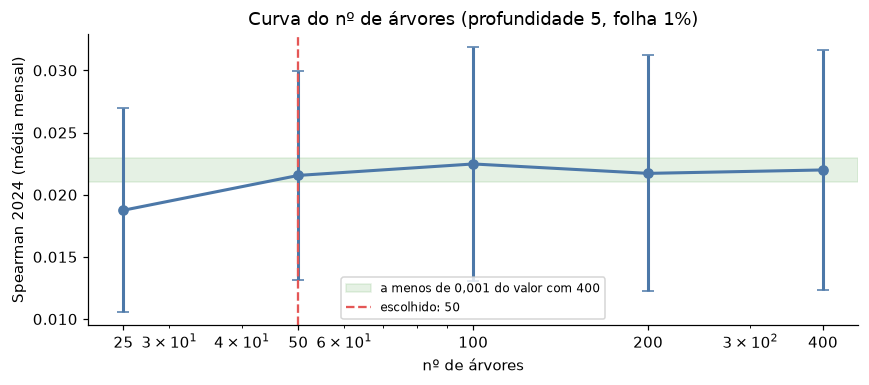

,spearman,t_robusto,ep
arvores,,,
25,0.01875,4.57953,0.00409
50,0.02155,5.10923,0.00422
100,0.02247,4.79470,0.00469
200,0.02172,4.58130,0.00474
400,0.02199,4.55094,0.00483


In [36]:
t0 = time.time()
prev_curva = {n: [] for n in ARVORES_CURVA}
for ini, fim in periodos_retreino(RETREINO_P4):
    tr, te = fatias(ini, fim)
    rf = RandomForestRegressor(n_estimators=ARVORES_CURVA[0], warm_start=True, n_jobs=-1, random_state=SEED,
                               max_samples=min(0.5, LIM_LINHAS_ARVORE / len(tr)), **CONFIG_ATUAL)
    for n in ARVORES_CURVA:
        rf.set_params(n_estimators=n)
        rf.fit(tr[FEATURES_P4], tr["alvo"])
        prev_curva[n].append(pd.DataFrame({"alvo": te["alvo"], "prev": rf.predict(te[FEATURES_P4]),
                                           "pts_prox": te["pts_prox"]}, index=te.index))

curva_arv = []
for n in ARVORES_CURVA:
    l, _ = painel(pd.concat(prev_curva[n]), CANDLE_P3, JANELA_P4, 0)
    curva_arv.append({"arvores": n, "spearman": l["spearman_mensal_medio"], "t_robusto": l["t_robusto"],
                      "ep": l["spearman_mensal_desvio"] / np.sqrt(12)})
curva_arv = pd.DataFrame(curva_arv).set_index("arvores")
ref = curva_arv["spearman"].iloc[-1]
N_ARVORES = int(curva_arv.index[(curva_arv["spearman"] - ref).abs() < 0.001][0])
print(f"Curva de árvores ({time.time() - t0:.0f}s) · escolhido: {N_ARVORES} árvores")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.errorbar(curva_arv.index, curva_arv["spearman"], yerr=2 * curva_arv["ep"], fmt="o-", color="#4C78A8", capsize=4, lw=2)
ax.axhspan(ref - 0.001, ref + 0.001, color="#54A24B", alpha=0.15, label="a menos de 0,001 do valor com 400")
ax.axvline(N_ARVORES, color="#E45756", ls="--", label=f"escolhido: {N_ARVORES}")
ax.set_xscale("log"); ax.set_xticks(ARVORES_CURVA, ARVORES_CURVA)
ax.set_xlabel("nº de árvores"); ax.set_ylabel("Spearman 2024 (média mensal)")
ax.set_title("Curva do nº de árvores (profundidade 5, folha 1%)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
curva_arv.round(5)

## P4.3 Grade de hiperparâmetros

- **Estágio A:** profundidade × % por folha, com `max_features = 1,0`.
- **Estágio B:** `max_features` = `sqrt` e 0,5 nas 2 melhores combinações do estágio A.
- **Estágio C:** extensão da grade, se o ótimo estiver na borda.

In [37]:
res_p4 = []

def roda_cfg(prof, folha, maxf, estagio):
    t1 = time.time()
    cfg = dict(max_depth=prof, min_samples_leaf=folha, max_features=maxf)
    prev, ntr, rho_tr = walk_forward_p4(cfg, N_ARVORES)
    l, mensal = painel(prev, CANDLE_P3, JANELA_P4, ntr)
    l.update(estagio=estagio, profundidade=prof, folha=folha, max_features=str(maxf),
             spearman_treino=rho_tr, gap_treino_valid=rho_tr - l["spearman"])
    res_p4.append(l)
    print(f"prof {prof} · folha {folha:.1%} · max_feat {str(maxf):<4} ρ={l['spearman_mensal_medio']:+.4f}  "
          f"t_rob={l['t_robusto']:+.2f}  ρ_treino={rho_tr:+.4f}  desvio prev/real={l['desvio_prev_sobre_real']:.3f}  "
          f"({time.time() - t1:.0f}s)")


t0 = time.time()
print("Estágio A: profundidade × folha (max_features = 1,0)")
for prof in PROFUNDIDADES:
    for folha in FOLHAS:
        roda_cfg(prof, folha, 1.0, "A")

top2_cfg = pd.DataFrame(res_p4).sort_values("spearman_mensal_medio", ascending=False).head(2)
print("\nEstágio B: max_features nas 2 melhores")
for _, l in top2_cfg.iterrows():
    for mf in MAX_FEATURES_B:
        roda_cfg(int(l["profundidade"]), float(l["folha"]), mf, "B")
# Estágio C: se a melhor configuração cair na borda da grade (folha máxima e/ou profundidade mínima),
# estende a grade nessa direção, mantendo o max_features da melhor
_r = pd.DataFrame(res_p4)
_m = _r.loc[_r["spearman_mensal_medio"].idxmax()]
_mf = _m["max_features"] if _m["max_features"] == "sqrt" else float(_m["max_features"])
_profs = [int(_m["profundidade"])] + ([int(_m["profundidade"]) - 1] if _m["profundidade"] == min(PROFUNDIDADES) else [])
_folhas = [float(_m["folha"])] + ([0.10, 0.20] if _m["folha"] == max(FOLHAS) else [])
_novas = [(p, f) for p in _profs for f in _folhas if (p, f) != (int(_m["profundidade"]), float(_m["folha"]))]
if _novas:
    print("")
    print(f"Estágio C: a melhor configuração está na borda da grade; estendendo (max_features {_m['max_features']})")
    for p, f in _novas:
        roda_cfg(p, f, _mf, "C")
r4 = pd.DataFrame(res_p4)
r4["ep_robusto"] = r4["spearman_mensal_desvio"] / np.sqrt(12)
print(f"\nGrade: {len(r4)} configurações ({time.time() - t0:.0f}s)")

Estágio A: profundidade × folha (max_features = 1,0)


prof 3 · folha 0.5% · max_feat 1.0  ρ=+0.0144  t_rob=+2.92  ρ_treino=+0.0471  desvio prev/real=0.018  (3s)


prof 3 · folha 1.0% · max_feat 1.0  ρ=+0.0186  t_rob=+4.07  ρ_treino=+0.0549  desvio prev/real=0.018  (3s)


prof 3 · folha 2.0% · max_feat 1.0  ρ=+0.0211  t_rob=+3.65  ρ_treino=+0.0501  desvio prev/real=0.017  (3s)


prof 3 · folha 5.0% · max_feat 1.0  ρ=+0.0248  t_rob=+4.68  ρ_treino=+0.0438  desvio prev/real=0.018  (3s)


prof 5 · folha 0.5% · max_feat 1.0  ρ=+0.0196  t_rob=+3.84  ρ_treino=+0.0593  desvio prev/real=0.024  (5s)


... (15 outputs left out)

prof 2 · folha 5.0% · max_feat sqrt ρ=+0.0263  t_rob=+4.88  ρ_treino=+0.0391  desvio prev/real=0.012  (1s)


prof 2 · folha 10.0% · max_feat sqrt ρ=+0.0239  t_rob=+4.13  ρ_treino=+0.0341  desvio prev/real=0.011  (1s)


C:\Users\anabi\AppData\Local\Temp\ipykernel_27180\1926188294.py:33: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho_tr.append(spearmanr(rf.predict(amostra[FEATURES_P4]), amostra["alvo"])[0])
C:\Users\anabi\AppData\Local\Temp\ipykernel_27180\1926188294.py:33: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho_tr.append(spearmanr(rf.predict(amostra[FEATURES_P4]), amostra["alvo"])[0])
C:\Users\anabi\AppData\Local\Temp\ipykernel_27180\4080726921.py:23: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  mensal = prev.groupby(prev.index.to_period("M")).apply(lambda d: spearmanr(d["prev"], d["alvo"])[0])


prof 2 · folha 20.0% · max_feat sqrt ρ=+nan  t_rob=+nan  ρ_treino=+nan  desvio prev/real=0.003  (0s)

Grade: 21 configurações (65s)


### Validação × treino (estágio A)

- **Esquerda:** Spearman em 2024, com o t robusto abaixo do número.
- **Direita:** diferença entre o Spearman no treino e na validação. Quanto maior, mais o modelo decorou o treino. Árvores fundas com folhas pequenas tendem a ter a maior diferença.

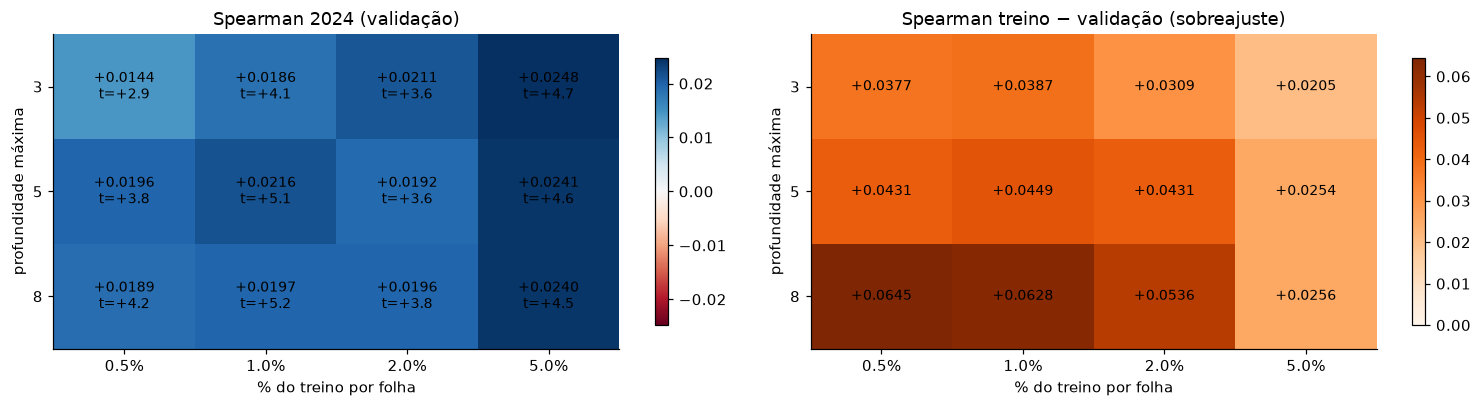

In [38]:
ra = r4[r4["estagio"] == "A"]
pv = ra.pivot(index="profundidade", columns="folha", values="spearman_mensal_medio")
pt = ra.pivot(index="profundidade", columns="folha", values="t_robusto")
pg = ra.pivot(index="profundidade", columns="folha", values="gap_treino_valid")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, tab, titulo, cmap, centro in [(axes[0], pv, "Spearman 2024 (validação)", "RdBu", 0.0),
                                      (axes[1], pg, "Spearman treino − validação (sobreajuste)", "Oranges", None)]:
    v = tab.values
    if centro is None:
        im = ax.imshow(v, cmap=cmap, vmin=0, vmax=np.nanmax(v), aspect="auto")
    else:
        a = np.nanmax(np.abs(v)); im = ax.imshow(v, cmap=cmap, vmin=-a, vmax=a, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), [f"{f:.1%}" for f in tab.columns])
    ax.set_yticks(range(tab.shape[0]), tab.index)
    ax.set_xlabel("% do treino por folha"); ax.set_ylabel("profundidade máxima")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            txt = f"{v[i, j]:+.4f}\nt={pt.values[i, j]:+.1f}" if centro is not None else f"{v[i, j]:+.4f}"
            ax.text(j, i, txt, ha="center", va="center", fontsize=9)
    ax.set_title(titulo); plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout(); plt.show()

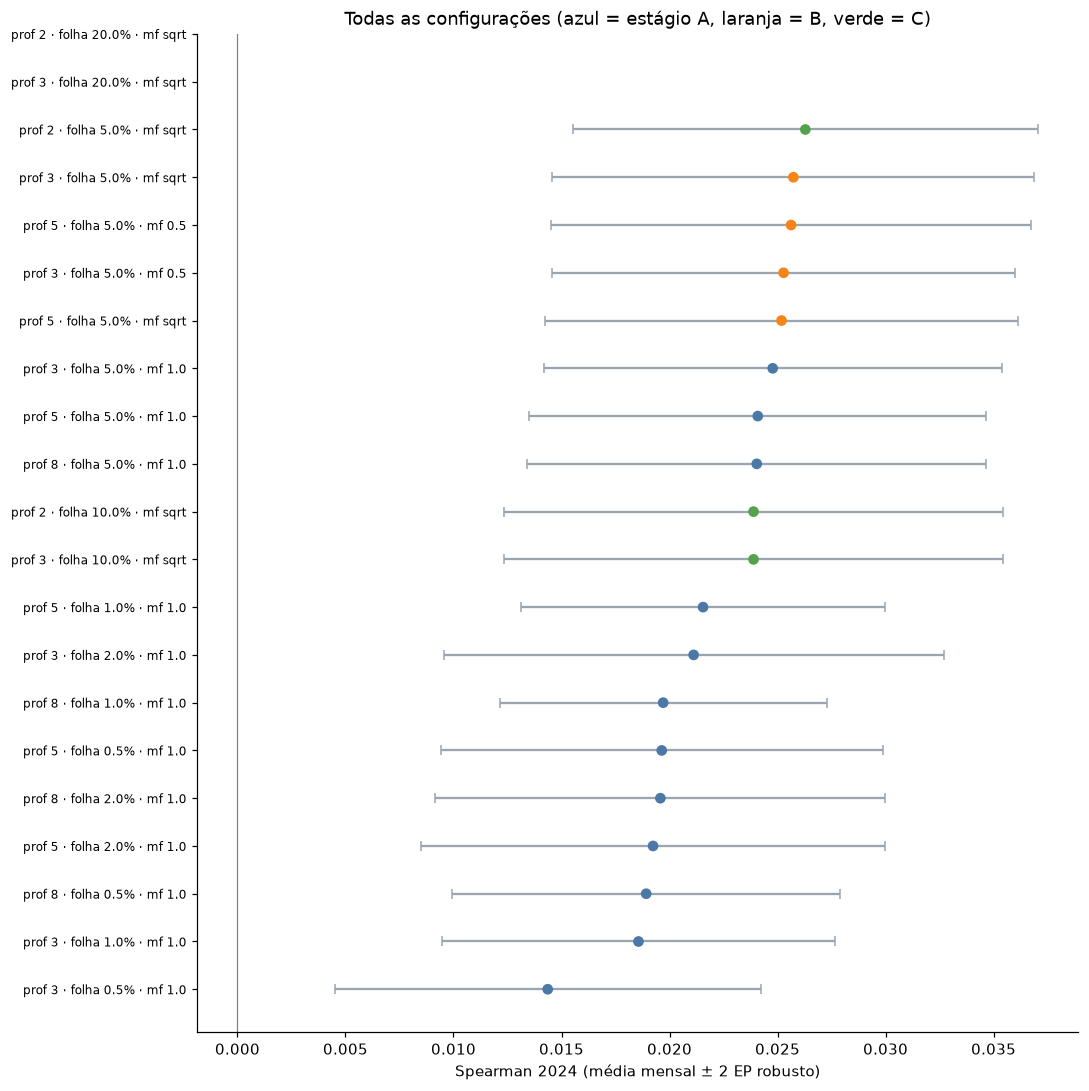

In [39]:
fig, ax = plt.subplots(figsize=(10, 0.42 * len(r4) + 1.2))
r4s = r4.sort_values("spearman_mensal_medio")
yy = np.arange(len(r4s))
cores = r4s["estagio"].map({"A": "#4C78A8", "B": "#F58518", "C": "#54A24B"}).values
ax.errorbar(r4s["spearman_mensal_medio"], yy, xerr=2 * r4s["ep_robusto"], fmt="none", ecolor="#9aa5b1", capsize=3)
ax.scatter(r4s["spearman_mensal_medio"], yy, c=cores, zorder=3)
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(yy, [f"prof {p} · folha {f:.1%} · mf {m}" for p, f, m in zip(r4s["profundidade"], r4s["folha"], r4s["max_features"])], fontsize=8)
ax.set_xlabel("Spearman 2024 (média mensal ± 2 EP robusto)")
ax.set_title("Todas as configurações (azul = estágio A, laranja = B, verde = C)")
plt.tight_layout(); plt.show()

## P4.4 Decisão

In [40]:
mf_ordem = {"sqrt": 0, "0.5": 1, "1.0": 2}
r4["ordem_mf"] = r4["max_features"].map(mf_ordem)
eleg4 = r4[(r4["t_robusto"] > 2) & (r4["theil_u"] <= TOL_THEIL)]
if len(eleg4):
    melhor4 = eleg4.loc[eleg4["spearman_mensal_medio"].idxmax()]
    emp4 = eleg4[eleg4["spearman_mensal_medio"] >= melhor4["spearman_mensal_medio"] - melhor4["ep_robusto"]]
    final4 = emp4.sort_values(["profundidade", "folha", "ordem_mf"], ascending=[True, False, True]).iloc[0]
    situacao_p4 = "sinal significativo"
else:
    melhor4 = final4 = r4.loc[r4["spearman_mensal_medio"].idxmax()]
    situacao_p4 = "SEM configuração com t robusto > 2"

mf_final = final4["max_features"] if final4["max_features"] == "sqrt" else float(final4["max_features"])
RF_FINAL = dict(n_estimators=N_ARVORES, max_depth=int(final4["profundidade"]),
                min_samples_leaf=float(final4["folha"]), max_features=mf_final,
                max_samples=0.5, lim_linhas_arvore=LIM_LINHAS_ARVORE)

print(r4.sort_values("spearman_mensal_medio", ascending=False)[
    ["estagio", "profundidade", "folha", "max_features", "theil_u", "spearman_mensal_medio", "ep_robusto",
     "t_robusto", "meses_rho_pos", "spearman_treino", "gap_treino_valid", "desvio_prev_sobre_real", "pts_brutos_op"]
].round(5).to_string(index=False))
print(f"\nMelhor configuração: prof {melhor4['profundidade']} · folha {melhor4['folha']:.1%} · max_features {melhor4['max_features']} "
      f"(ρ = {melhor4['spearman_mensal_medio']:+.4f})")
print(f"Escolhida (regra: a até 1 EP, a mais simples): prof {RF_FINAL['max_depth']} · folha {RF_FINAL['min_samples_leaf']:.1%} · "
      f"max_features {RF_FINAL['max_features']} · {N_ARVORES} árvores  ·  {situacao_p4}")
print(f"  Spearman 2024 = {final4['spearman_mensal_medio']:+.4f} ± {final4['ep_robusto']:.4f} · t robusto = {final4['t_robusto']:+.2f} · "
      f"meses ρ>0 = {final4['meses_rho_pos']}/12 · ganho bruto = {final4['pts_brutos_op']:+.2f} pts/op")
print(f"  Referência da análise de dados: n mínimo por folha ≈ {n_med:,.0f} candles (janela = {N_treino:,}): "
      f"folhas grandes e árvores rasas")

saida_p4 = {"candle_min": CANDLE_P3, "features": FEATURES_P4, "janela": JANELA_P4, "retreino": RETREINO_P4,
            "rf": RF_FINAL, "situacao": situacao_p4}
(PASTA_RES / "passo4_hiperparametros.json").write_text(json.dumps(saida_p4, indent=2, ensure_ascii=False))
r4.to_csv(PASTA_RES / "passo4_grade.csv", index=False)
curva_arv.to_csv(PASTA_RES / "passo4_curva_arvores.csv")
tab_folha.to_csv(PASTA_RES / "passo4_folha_minima.csv")
print(f"\nSalvo em {PASTA_RES}")

estagio  profundidade  folha max_features  theil_u  spearman_mensal_medio  ep_robusto  t_robusto  meses_rho_pos  spearman_treino  gap_treino_valid  desvio_prev_sobre_real  pts_brutos_op
      C             2  0.050         sqrt  0.99994                0.02629     0.00538    4.88230             11          0.03905           0.01600                 0.01183        0.37314
      B             3  0.050         sqrt  0.99994                0.02573     0.00558    4.61285             11          0.04216           0.01907                 0.01398        0.35148
      B             5  0.050          0.5  0.99993                0.02563     0.00555    4.61549             10          0.04679           0.02269                 0.01714        0.41694
      B             3  0.050          0.5  0.99994                0.02528     0.00536    4.71897             11          0.04330           0.01980                 0.01609        0.35884
      B             5  0.050         sqrt  0.99995                0.02

## P4.5 Como ler e próximos passos

**Leitura do resultado**
- **Análise de dados (P4.1).** Pela conta da folha mínima, o efeito de cada feature é tão pequeno que uma folha precisaria de mais candles do que a janela inteira para ter média significativa. O RF só funciona pela média de muitas folhas e árvores. Os dados já apontavam folhas grandes e árvores rasas, e a grade confirmou.
- **Árvores (P4.2).** Depois do platô, mais árvores só custam tempo.
- **Sobreajuste (P4.3).** Se a configuração escolhida tem o Spearman de treino muito acima do de validação, o modelo ainda decora ruído. Uma folha maior ou uma árvore mais rasa ajudam.

**Neste ponto o modelo está definido:** candle, features, janela, retreino e hiperparâmetros (salvos em `resultados/passo4_hiperparametros.json`).

**Próximos passos do plano**
1. **Passo 5 — Regras de compra e venda**, sobre as previsões de 2024 do modelo definido:
   - limiar de entrada pelos decis da previsão;
   - lado (compra, venda ou os dois);
   - saída (próximo candle, segurar k candles, TP/stop pela volatilidade);
   - filtros de horário e de volatilidade;
   - comparação com sinais aleatórios nos mesmos candles.
2. **Passo 6 — Confirmação, congelamento e validação única** em 01/2025 → 03/2026, com os três cenários de custo.

**Limitações deste passo**
- O estágio B só testou `max_features` nas 2 melhores combinações do estágio A.
- Com retreino semestral, cada configuração é avaliada com só 2 modelos. O t robusto continua usando os 12 meses de previsão.
- O δ da folha mínima vem de features isoladas. Combinadas no RF, elas podem ter efeitos um pouco maiores.

# Passo 5 — Regras de compra, venda, take profit e stop loss

**Pergunta:** com o RF congelado, existe regra de operação com resultado líquido positivo?

- **Desenvolvimento:** walk-forward 2022–2023 (grade em etapas). **Seleção:** 2024, só 3 finalistas. 2025 em diante não é usado.
- **Execução:** sinal no fechamento de *t*, entrada na abertura de *t+1*, uma posição por vez, 5 pts de custo. TP e stop no mesmo candle contam como stop.
- **Critério da grade:** média diária líquida − 1 erro-padrão (mensal), com ≥ 100 operações por ano e resultado positivo em 2022 e 2023.
- **Ressalva:** os hiperparâmetros vieram de 2024, e 24 combinações exploratórias (saída por tempo, sinais sobrepostos) já haviam sido vistas em 2024.

Precisa das células de configuração, carga e definição dos passos 1 e 2 (`m1`, `wdo_m1`, `monta_base_p2`).

## P5.0 Configuração e previsões walk-forward

In [41]:
_p4 = json.loads((PASTA_RES / "passo4_hiperparametros.json").read_text())
FEATS_P5, RF_P5 = _p4["features"], _p4["rf"]
FIM_P5 = pd.Timestamp("2025-01-01")                  # nada daqui em diante entra no passo 5
m1_p5, wdo_p5 = m1[m1.index < FIM_P5], wdo_m1[wdo_m1.index < FIM_P5]
base5 = monta_base_p2(m1_p5, 1, wdo_p5)
assert base5.index.max() < FIM_P5

FOLHAS_P5 = [0.10, 0.05]
CORTES_P5 = [0.30, 0.10, 0.05]                       # fração total das previsões nas duas caudas
cortes_tempo = pd.to_datetime(["2022-01-01", "2022-07-01", "2023-01-01", "2023-07-01", "2024-01-01", "2024-07-01", "2025-01-01"])

partes = []
for folha in FOLHAS_P5:
    for ini, fim in zip(cortes_tempo[:-1], cortes_tempo[1:]):
        tr = base5[(base5.index >= ini - pd.DateOffset(months=_p4["janela"])) & (base5.index < ini)]
        te = base5[(base5.index >= ini) & (base5.index < fim)]
        rf = RandomForestRegressor(n_estimators=RF_P5["n_estimators"], max_depth=RF_P5["max_depth"], min_samples_leaf=folha,
                                   max_features=RF_P5["max_features"], max_samples=min(0.5, RF_P5["lim_linhas_arvore"] / len(tr)),
                                   n_jobs=-1, random_state=SEED).fit(tr[FEATS_P5], tr["alvo"])
        p_tr = rf.predict(tr[FEATS_P5])
        d = pd.DataFrame({"folha": folha, "prev": rf.predict(te[FEATS_P5]), "vol_20": te["vol_20"],
                          "vol_med_treino": tr["vol_20"].median()}, index=te.index)
        for c in CORTES_P5:                          # limiares só com o treino
            d[f"q_sup_{c:g}"], d[f"q_inf_{c:g}"] = np.quantile(p_tr, [1 - c / 2, c / 2])
        partes.append(d)
prev5 = pd.concat(partes)
prev5.to_csv(PASTA_RES / "passo5_previsoes.csv")

ref = pd.read_csv(PASTA_RES / "passo4_modelo_final_previsoes_2024.csv", parse_dates=["dt"]).set_index("dt")["prev"]
meu = prev5[(prev5["folha"] == 0.10) & (prev5.index.year == 2024)]["prev"]
dif = (meu - ref).abs()
print(f"Reprodução do passo 4: linhas {len(meu)} x {len(ref)} · maior diferença {dif.max():.1e}")
assert len(meu) == len(ref) and dif.notna().all() and dif.max() < 1e-10
print("Fração de 2022–2024 além dos limiares (esperado: corte/2 por lado):")
print(pd.DataFrame({(f, c): {"compra": (g["prev"] >= g[f"q_sup_{c:g}"]).mean(), "venda": (g["prev"] <= g[f"q_inf_{c:g}"]).mean()}
      for f, g in prev5.groupby("folha") for c in CORTES_P5}).T.round(3).to_string())

Reprodução do passo 4: linhas 141302 x 141302 · maior diferença 1.0e-16
Fração de 2022–2024 além dos limiares (esperado: corte/2 por lado):
           compra  venda
0.05 0.30   0.166  0.117
     0.10   0.059  0.036
     0.05   0.030  0.017
0.10 0.30   0.183  0.118
     0.10   0.071  0.035
     0.05   0.038  0.017


## P5.1 Motor de simulação e testes

In [42]:
TICK = 5
ULT_ENTRADA, ULT_CANDLE = 17 * 60 + 50, 18 * 60 + 19      # entra até 17:50; zera no fechamento do candle de 18:19 (18:20)


class Mercado:
    """Candles em arrays; fim[i] = último candle utilizável do pregão de i."""
    def __init__(self, candles):
        self.idx = candles.index
        self.o, self.h, self.l, self.c = (candles[x].to_numpy(float) for x in ("open", "high", "low", "close"))
        self.minuto = np.asarray(candles.index.hour * 60 + candles.index.minute)
        self.dia = candles.index.normalize().to_numpy()
        pos = pd.Series(np.arange(len(candles)), index=self.dia)
        util = pos[self.minuto <= ULT_CANDLE].groupby(level=0).max()
        self.fim = pd.Series(self.dia).map(util).fillna(-1).to_numpy(int)

    def pode_entrar(self, t):                              # sinal em t, entrada em t+1
        e = t + 1
        return e < len(self.o) and self.dia[e] == self.dia[t] and self.minuto[e] <= ULT_ENTRADA and e <= self.fim[e]

    def opera(self, t, lado, H, dist_tp, dist_sl):
        """Retorna (i_saida, pontos, motivo, mfe, mae). lado = +1 compra, -1 venda; dist None = sem."""
        e = t + 1
        u = min(e + H - 1, self.fim[e])
        ent = self.o[e]
        hi, lo = self.h[e:u + 1], self.l[e:u + 1]
        fav, adv = (hi - ent, ent - lo) if lado > 0 else (ent - lo, hi - ent)
        js = np.flatnonzero(adv >= dist_sl) if dist_sl else ()
        jt = np.flatnonzero(fav >= dist_tp) if dist_tp else ()
        s = js[0] if len(js) else 10**9
        g = jt[0] if len(jt) else 10**9
        if s <= g and s < 10**9:
            gap = lado * (self.o[e + s] - ent)             # gap além do stop: sai na abertura
            pts, j, mot = min(-dist_sl, gap), s, "stop"
        elif g < 10**9:
            pts, j, mot = dist_tp, g, "tp"
        else:
            j = u - e
            pts, mot = lado * (self.c[u] - ent), "tempo" if u == e + H - 1 else "fim_do_dia"
        return e + j, pts, mot, max(fav[:j + 1].max(), 0), max(adv[:j + 1].max(), 0)


def distancia(m, vol20, fech, H):
    return None if not m else max(TICK, TICK * round(m * vol20 / 100 * fech * np.sqrt(H) / TICK))


def sinais(p, regra):
    c = f"{regra['corte']:g}"
    s = np.where(p["prev"] >= p[f"q_sup_{c}"], 1, np.where(p["prev"] <= p[f"q_inf_{c}"], -1, 0))
    if regra["lado"] == "compra":
        s = np.where(s > 0, s, 0)
    if regra["lado"] == "venda":
        s = np.where(s < 0, s, 0)
    if regra["filtro"] == "manha":
        s = np.where(p.index.hour < 12, s, 0)
    if regra["filtro"] == "vol_alta":
        s = np.where(p["vol_20"] > p["vol_med_treino"], s, 0)
    return s


def simula(p, mk, regra):
    """p: previsões (uma folha, um período); mk: Mercado."""
    s = sinais(p, regra)
    pos = mk.idx.get_indexer(p.index)
    vol = p["vol_20"].to_numpy()
    ops, livre = [], -1
    for k in np.flatnonzero(s):
        t = pos[k]
        if t < livre or t < 0 or not mk.pode_entrar(t):
            continue
        dtp = distancia(regra["tp"], vol[k], mk.c[t], regra["H"])
        dsl = distancia(regra["sl"], vol[k], mk.c[t], regra["H"])
        i, pts, mot, mfe, mae = mk.opera(t, s[k], regra["H"], dtp, dsl)
        ops.append((mk.idx[t], mk.idx[t + 1], mk.idx[i], s[k], pts, mot, mfe, mae, t, vol[k]))
        livre = i
    return pd.DataFrame(ops, columns=["sinal", "entrada", "saida", "lado", "pts", "motivo", "mfe", "mae", "t", "vol_20"])


# ----- testes com candles artificiais -----
def _mk(ohlc, ini="2022-01-03 10:00"):
    return Mercado(pd.DataFrame(ohlc, columns=["open", "high", "low", "close"],
                                index=pd.date_range(ini, periods=len(ohlc), freq="min"), dtype=float))


F = (1000, 1000, 1000, 1000)
for sg in (1, -1):
    def esp(c):                                           # espelha o preço para o lado vendido
        o, h, l, f = c
        return c if sg > 0 else (2000 - o, 2000 - l, 2000 - h, 2000 - f)

    def roda(cs, H, tp, sl, ini="2022-01-03 10:00"):
        return _mk([esp(c) for c in cs], ini).opera(0, sg, H, tp, sl)[:3]

    assert roda([F, (1000, 1060, 990, 1050), F], 2, 50, 50) == (1, 50, "tp")
    assert roda([F, (1000, 1010, 940, 950), F], 2, 50, 50) == (1, -50, "stop")
    assert roda([F, (1000, 1060, 940, 1000), F], 2, 50, 50) == (1, -50, "stop")          # ambos no candle
    assert roda([F, F, (900, 910, 890, 900)], 2, 50, 50) == (2, -100, "stop")            # gap além do stop
    assert roda([F, F, (1100, 1110, 1090, 1100)], 2, 50, 50) == (2, 50, "tp")            # gap a favor: preço-alvo
    assert roda([F, F, (1000, 1030, 990, 1020), F], 2, 50, 50) == (2, 20, "tempo")
    assert roda([F] * 15, 60, None, None, "2022-01-03 18:10")[::2] == (9, "fim_do_dia")  # candle de 18:19
_t = _mk([F] * 5, "2022-01-03 17:48")
assert _t.pode_entrar(0) and _t.pode_entrar(1) and not _t.pode_entrar(2)
_d = pd.DataFrame([F] * 4, columns=["open", "high", "low", "close"], dtype=float,
                  index=pd.to_datetime(["2022-01-03 10:00", "2022-01-03 10:01", "2022-01-04 10:00", "2022-01-04 10:01"]))
assert not Mercado(_d).pode_entrar(1)                                                  # não atravessa pregão
_mm = _mk([F] * 20)
_p = pd.DataFrame({"prev": 1.0, "q_sup_0.1": 0.5, "q_inf_0.1": -0.5, "vol_20": 0.05, "vol_med_treino": 0.01}, index=_mm.idx)
_o = simula(_p, _mm, dict(corte=0.1, lado="ambos", H=5, tp=None, sl=None, filtro="nenhum"))
assert (_o["entrada"].iloc[1:].values > _o["saida"].iloc[:-1].values).all() and len(_o) == 4   # sem sobreposição
print("Testes do motor: ok (compra e venda)")

# sem futuro: truncar os candles depois de t não muda as features em t
_corte = pd.Timestamp("2023-03-15 13:00")
_tr = monta_base_p2(m1_p5[m1_p5.index <= _corte], 1, wdo_p5[wdo_p5.index <= _corte])
_i = _tr.index[-500:]
assert np.allclose(_tr.loc[_i, FEATS_P5], base5.loc[_i, FEATS_P5], rtol=0, atol=1e-10)
print("Teste de futuro: ok")

Testes do motor: ok (compra e venda)


Teste de futuro: ok


## P5.2 Grade em 2022–2023

In [43]:
mk = Mercado(m1_p5[m1_p5.index >= "2022-01-01"])
dias_todos = pd.DatetimeIndex(np.unique(mk.dia))


def diario(ops, dias, custo=CUSTO_PTS):
    liq = (ops["pts"] - custo).groupby(ops["entrada"].dt.normalize()).sum()
    return liq.reindex(dias, fill_value=0.0)


def ep_mensal(d):
    m = d.groupby(d.index.to_period("M")).mean()
    return m.std(ddof=1) / np.sqrt(len(m))


def mede(ops, dias):
    d = diario(ops, dias)
    r = {"n_ops": len(ops), "bruto_op": ops["pts"].mean(), "liq_op": ops["pts"].mean() - CUSTO_PTS,
         "liq_dia": d.mean(), "ep_dia": ep_mensal(d), "score": d.mean() - ep_mensal(d),
         "acerto": (ops["pts"] > 0).mean()}
    assert abs(d.sum() - (ops["pts"] - CUSTO_PTS).sum()) < 1e-6
    assert (ops["entrada"].dt.normalize() == ops["saida"].dt.normalize()).all()
    for a in sorted(set(dias.year)):
        r[f"n_{a}"] = int((ops["entrada"].dt.year == a).sum())
        r[f"liq_dia_{a}"] = d[d.index.year == a].mean()
    return r


dias_dev = dias_todos[dias_todos.year < 2024]
P_dev = {f: g[g.index.year < 2024] for f, g in prev5.groupby("folha")}
CAMPOS = ["folha", "corte", "lado", "H", "tp", "sl", "filtro"]
ENTRADA = ["folha", "corte", "lado", "H"]
grade, dev_diario = [], {}


def chave(r, campos=CAMPOS):
    return tuple(r[c] for c in campos)


def testa(etapa, regra):
    if chave(regra) in dev_diario:
        return
    ops = simula(P_dev[regra["folha"]], mk, regra)
    dev_diario[chave(regra)] = diario(ops, dias_dev)
    grade.append({"etapa": etapa, **regra, **mede(ops, dias_dev)})


def elegivel(g):
    return (g["n_2022"] >= 100) & (g["n_2023"] >= 100) & (g["liq_dia_2022"] > 0) & (g["liq_dia_2023"] > 0)


def ordena(g):                                            # elegíveis primeiro; depois o score
    return g.assign(elegivel=elegivel(g)).sort_values(["elegivel", "score"], ascending=False)


def regra_de(l):
    return {c: (None if c in ("tp", "sl") and pd.isna(l[c]) else l[c]) for c in CAMPOS}


def n_saidas(r):
    return (r["tp"] is not None) + (r["sl"] is not None)


t0 = time.time()
for f in FOLHAS_P5:
    for c in CORTES_P5:
        for lado in ("ambos", "compra", "venda"):
            for H in (30, 60, 120):
                testa("A", dict(folha=f, corte=c, lado=lado, H=H, tp=None, sl=None, filtro="nenhum"))
topA = ordena(pd.DataFrame(grade)).head(2)
for _, l in topA.iterrows():
    for tp in (None, 1.0, 1.5):
        for sl in (None, 1.0, 1.5):
            testa("B", {**regra_de(l), "tp": tp, "sl": sl})

# base da etapa C: melhor de B; empate (diferença pareada dentro de 1 EP) fica com menos saídas
gB = pd.DataFrame(grade)
pais = {chave(l, ENTRADA) for _, l in topA.iterrows()}
candB = ordena(gB[[chave(l, ENTRADA) in pais for _, l in gB.iterrows()]])
melhorB = regra_de(candB.iloc[0])
baseC = melhorB
for _, l in candB.iterrows():
    r = regra_de(l)
    if chave(r, ENTRADA) != chave(melhorB, ENTRADA):
        continue
    dd = dev_diario[chave(melhorB)] - dev_diario[chave(r)]
    if n_saidas(r) < n_saidas(baseC) and dd.mean() <= ep_mensal(dd):
        baseC = r
for filtro in ("manha", "vol_alta"):
    testa("C", {**baseC, "filtro": filtro})

grade = pd.DataFrame(grade)
grade["elegivel"] = elegivel(grade)
grade.to_csv(PASTA_RES / "passo5_grade.csv", index=False)
print(f"{len(grade)} combinações ({time.time() - t0:.0f}s) · elegíveis: {int(grade['elegivel'].sum())} · "
      f"líquido/dia > 0 no total: {int((grade['liq_dia'] > 0).sum())}")
print("Base da etapa C:", baseC)
VER = ["etapa"] + CAMPOS + ["n_ops", "bruto_op", "liq_op", "liq_dia", "ep_dia", "score", "liq_dia_2022", "liq_dia_2023", "elegivel"]
print(ordena(grade)[VER].head(20).round(2).to_string(index=False))

72 combinações (5s) · elegíveis: 45 · líquido/dia > 0 no total: 60
Base da etapa C: {'folha': 0.05, 'corte': 0.05, 'lado': 'ambos', 'H': 120, 'tp': None, 'sl': None, 'filtro': 'nenhum'}
etapa  folha  corte   lado   H  tp  sl filtro  n_ops  bruto_op  liq_op  liq_dia  ep_dia  score  liq_dia_2022  liq_dia_2023  elegivel
    B   0.05   0.05  ambos 120 1.5 NaN nenhum   1344     38.11   33.11   112.37   46.15  66.22        126.62         90.23      True
    B   0.05   0.05  ambos 120 NaN 1.5 nenhum   1334     41.90   36.90   124.29   59.84  64.45        134.38        108.61      True
    B   0.05   0.10  ambos  60 1.5 NaN nenhum   2885     19.37   14.37   104.71   40.53  64.18        123.53         75.45      True
    B   0.05   0.05  ambos 120 NaN 1.0 nenhum   1424     39.21   34.21   123.01   61.63  61.37        141.97         93.52      True
    A   0.05   0.05  ambos 120 NaN NaN nenhum   1283     45.06   40.06   129.79   71.54  58.24        154.29         91.68      True
    B   0.05   0

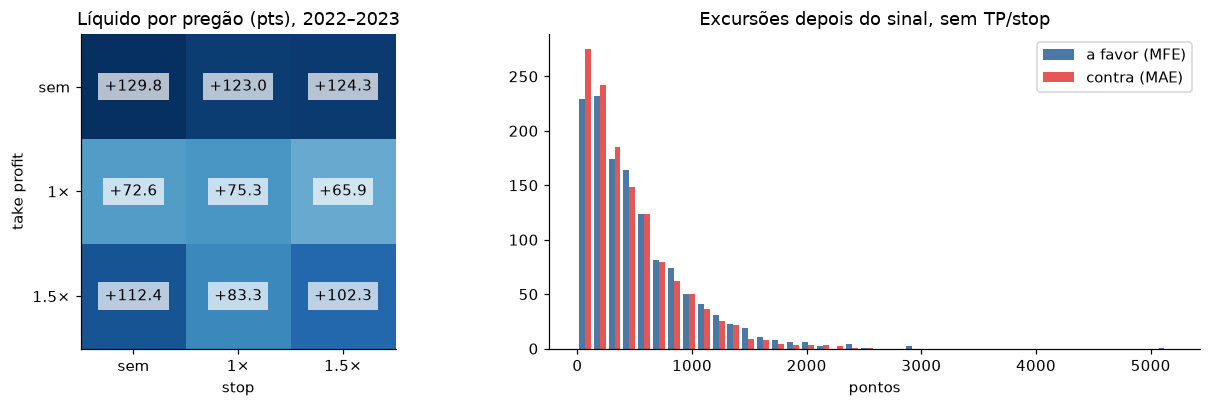

In [44]:
_tp = grade[np.array([chave(l, ENTRADA) == chave(melhorB, ENTRADA) for _, l in grade.iterrows()]) & (grade["filtro"] == "nenhum")]
pv = _tp.assign(tp=_tp["tp"].fillna(0).astype(float), sl=_tp["sl"].fillna(0).astype(float)).pivot(index="tp", columns="sl", values="liq_dia")
ops_base = simula(P_dev[melhorB["folha"]], mk, {**melhorB, "tp": None, "sl": None})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
v = np.abs(pv.values).max()
ax[0].imshow(pv.values, cmap="RdBu", vmin=-v, vmax=v)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax[0].text(j, i, f"{pv.values[i, j]:+.1f}", ha="center", va="center", bbox=dict(fc="white", ec="none", alpha=0.7))
rot = lambda a: ["sem" if x == 0 else f"{x:g}×" for x in a]
ax[0].set_xticks(range(len(pv.columns)), rot(pv.columns))
ax[0].set_yticks(range(len(pv.index)), rot(pv.index))
ax[0].set_xlabel("stop"); ax[0].set_ylabel("take profit"); ax[0].set_title("Líquido por pregão (pts), 2022–2023")
ax[1].hist([ops_base["mfe"], ops_base["mae"]], bins=40, label=["a favor (MFE)", "contra (MAE)"], color=["#4C78A8", "#E45756"])
ax[1].set_xlabel("pontos"); ax[1].set_title("Excursões depois do sinal, sem TP/stop"); ax[1].legend()
plt.tight_layout(); plt.show()

## P5.3 Seleção em 2024: só os 3 finalistas

Referências: 2.000 sorteios de direção nas mesmas entradas; comprar/vender sempre nas mesmas entradas; e mesmo lado e horário em outro pregão do mesmo mês (decide nas regras de um lado só, em que "vender sempre" seria a própria regra).

In [45]:
dias_24 = dias_todos[dias_todos.year == 2024]
P_24 = {f: g[g.index.year == 2024] for f, g in prev5.groupby("folha")}
finalistas = [regra_de(l) for _, l in ordena(grade).head(3).iterrows()]
rng5 = np.random.default_rng(SEED)
N_SORTEIOS = 2000
linhas, ops_24, nulas = [], {}, {}


def pts_em(t, lado, vol, r):
    return mk.opera(t, lado, r["H"], distancia(r["tp"], vol, mk.c[t], r["H"]), distancia(r["sl"], vol, mk.c[t], r["H"]))[1]


for k, r in enumerate(finalistas):
    p = P_24[r["folha"]]
    ops = simula(p, mk, r)
    ops_24[k] = ops
    m = mede(ops, dias_24)
    L = np.array([pts_em(t, 1, v, r) for t, v in zip(ops["t"], ops["vol_20"])])
    S = np.array([pts_em(t, -1, v, r) for t, v in zip(ops["t"], ops["vol_20"])])
    assert np.allclose(np.where(ops["lado"] > 0, L, S), ops["pts"])
    sort = np.where(rng5.random((N_SORTEIOS, len(ops))) < 0.5, L, S)
    nulas[k] = sort
    # mesmo lado e minuto, pregão sorteado do mesmo mês
    vol_em = p["vol_20"].to_dict()
    por = {}
    for t_ in mk.idx.get_indexer(p.index):
        por.setdefault((mk.idx[t_].month, mk.minuto[t_]), []).append(t_)
    cache, outros = {}, np.zeros((len(ops), N_SORTEIOS))
    for a, (t, lado) in enumerate(zip(ops["t"], ops["lado"])):
        cand = []
        for t_ in por[(mk.idx[t].month, mk.minuto[t])]:
            if mk.pode_entrar(t_):
                if (t_, lado) not in cache:
                    cache[(t_, lado)] = pts_em(t_, lado, vol_em[mk.idx[t_]], r)
                cand.append(cache[(t_, lado)])
        outros[a] = rng5.choice(cand, N_SORTEIOS)
    mens = diario(ops, dias_24).groupby(dias_24.to_period("M")).sum()
    sem = mede(simula(p, mk, {**r, "tp": None, "sl": None}), dias_24)
    ref_lado = max(L.mean(), S.mean()) if r["lado"] == "ambos" else outros.mean()
    m.update(finalista=k + 1, **r, meses_pos=int((mens > 0).sum()), pctl_aleatorio=100 * (sort.mean(1) < ops["pts"].mean()).mean(),
             aleatorio_bruto=sort.mean(), comprar_sempre=L.mean(), vender_sempre=S.mean(),
             mesmo_horario=outros.mean(), pctl_mesmo_horario=100 * (outros.mean(0) < ops["pts"].mean()).mean(),
             sem_tp_sl_liq_dia=sem["liq_dia"], custo_equilibrio=m["bruto_op"])
    m["bate_referencia"] = bool(ops["pts"].mean() > ref_lado)
    m["aprovada"] = bool(m["liq_op"] > 0 and m["n_ops"] >= 100 and m["pctl_aleatorio"] >= 95
                         and m["meses_pos"] >= 7 and m["bate_referencia"])
    linhas.append(m)
fin = pd.DataFrame(linhas).set_index("finalista")
fin.to_csv(PASTA_RES / "passo5_finalistas_2024.csv")
print(fin.T.to_string())

finalista                   1          2           3
n_ops                     983       1003        1995
bruto_op            -3.550356   6.799601   -1.411028
liq_op              -8.550356   1.799601   -6.411028
liq_dia            -33.486056   7.191235  -50.956175
ep_dia              39.164964  44.512588   66.753691
score               -72.65102 -37.321353 -117.709867
acerto               0.505595   0.508475    0.516291
n_2024                    983       1003        1995
liq_dia_2024       -33.486056   7.191235  -50.956175
folha                    0.05       0.05        0.05
corte                    0.05       0.05         0.1
lado                    ambos      ambos       ambos
H                         120        120          60
tp                        1.5        NaN         1.5
sl                        NaN        1.5         NaN
filtro                 nenhum     nenhum      nenhum
meses_pos                   5          7           5
pctl_aleatorio           45.1       57.4      

## P5.4 Decisão

Regra: {'folha': 0.05, 'corte': 0.05, 'lado': 'ambos', 'H': 120, 'tp': None, 'sl': 1.5, 'filtro': 'nenhum'}
NÃO OPERAR: a regra não passou nos critérios (congelada só como registro)


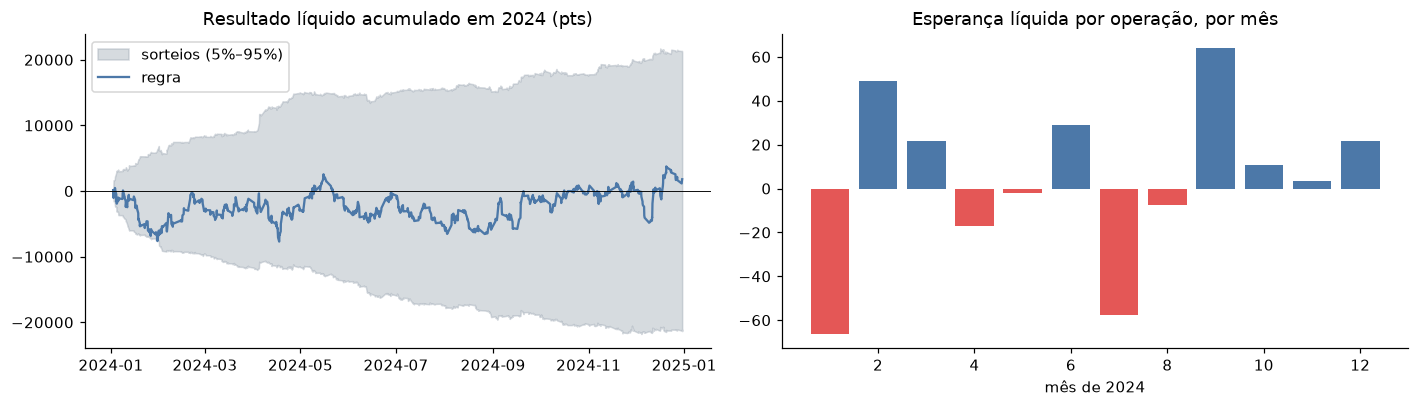

In [46]:
iv = int(fin["score"].idxmax()) - 1
aprov = bool(fin.iloc[iv]["aprovada"])
ops_24[iv].drop(columns="t").to_csv(PASTA_RES / "passo5_operacoes_2024.csv", index=False)
situacao_p5 = "APROVADA" if aprov else "NÃO OPERAR: a regra não passou nos critérios (congelada só como registro)"
(PASTA_RES / "passo5_regra.json").write_text(json.dumps({
    "regra": finalistas[iv], "situacao": situacao_p5, "aprovada": aprov, "n_combinacoes_grade": len(grade),
    "n_elegiveis_2022_2023": int(grade["elegivel"].sum()), "n_finalistas_2024": len(finalistas),
    "n_exploratorias_2024": 24}, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Regra:", finalistas[iv])
print(situacao_p5)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ac = (ops_24[iv]["pts"] - CUSTO_PTS).cumsum().to_numpy()
na = (nulas[iv] - CUSTO_PTS).cumsum(1)
ax[0].fill_between(ops_24[iv]["entrada"], *np.quantile(na, [0.05, 0.95], axis=0), color="#9aa5b1", alpha=0.4, label="sorteios (5%–95%)")
ax[0].plot(ops_24[iv]["entrada"], ac, color="#4C78A8", label="regra")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_title("Resultado líquido acumulado em 2024 (pts)"); ax[0].legend()
em = (ops_24[iv]["pts"] - CUSTO_PTS).groupby(ops_24[iv]["entrada"].dt.month).mean()
ax[1].bar(em.index, em.values, color=np.where(em > 0, "#4C78A8", "#E45756"))
ax[1].set_title("Esperança líquida por operação, por mês"); ax[1].set_xlabel("mês de 2024")
plt.tight_layout(); plt.show()

# Passo 7 — Validação do RF (rodada única)

01/2025 → 03/2026, com a regra congelada em `passo5_regra.json` e custo de 5 pts. Rodada em 23/11/2026; a regra não tinha sido aprovada em 2024. Não reexecutar com outras regras: o período já foi visto.

In [12]:
r7 = json.loads((PASTA_RES / "passo5_regra.json").read_text(encoding="utf-8"))["regra"]
INI_P7, FIM_P7 = pd.Timestamp("2025-01-01"), pd.Timestamp("2026-04-01")     # reserva (04/2026 em diante) fica fora
m1_p7, wdo_p7 = m1[m1.index < FIM_P7], wdo_m1[wdo_m1.index < FIM_P7]
base7 = monta_base_p2(m1_p7, 1, wdo_p7)
ct = pd.to_datetime(["2025-01-01", "2025-07-01", "2026-01-01", "2026-04-01"])
c7 = r7["corte"]
partes = []
for ini, fim in zip(ct[:-1], ct[1:]):
    tr = base7[(base7.index >= ini - pd.DateOffset(months=_p4["janela"])) & (base7.index < ini)]
    te = base7[(base7.index >= ini) & (base7.index < fim)]
    rf = RandomForestRegressor(n_estimators=RF_P5["n_estimators"], max_depth=RF_P5["max_depth"], min_samples_leaf=r7["folha"],
                               max_features=RF_P5["max_features"], max_samples=min(0.5, RF_P5["lim_linhas_arvore"] / len(tr)),
                               n_jobs=-1, random_state=SEED).fit(tr[FEATS_P5], tr["alvo"])
    p_tr = rf.predict(tr[FEATS_P5])
    d = pd.DataFrame({"prev": rf.predict(te[FEATS_P5]), "alvo": te["alvo"], "vol_20": te["vol_20"], "vol_med_treino": tr["vol_20"].median()}, index=te.index)
    d[f"q_sup_{c7:g}"], d[f"q_inf_{c7:g}"] = np.quantile(p_tr, [1 - c7 / 2, c7 / 2])
    partes.append(d)
prev7 = pd.concat(partes)
mk7 = Mercado(m1_p7[m1_p7.index >= INI_P7])
dias7 = pd.DatetimeIndex(np.unique(mk7.dia))
ops7 = simula(prev7, mk7, r7)
m7 = mede(ops7, dias7)
def _pts(t, lado, v):
    return mk7.opera(t, lado, r7["H"], distancia(r7["tp"], v, mk7.c[t], r7["H"]), distancia(r7["sl"], v, mk7.c[t], r7["H"]))[1]
L7 = np.array([_pts(t, 1, v) for t, v in zip(ops7["t"], ops7["vol_20"])])
S7 = np.array([_pts(t, -1, v) for t, v in zip(ops7["t"], ops7["vol_20"])])
assert np.allclose(np.where(ops7["lado"] > 0, L7, S7), ops7["pts"])
sort7 = np.where(np.random.default_rng(SEED).random((2000, len(ops7))) < 0.5, L7, S7).mean(1)
mens_rho = prev7.groupby(prev7.index.to_period("M")).apply(lambda g: spearmanr(g["prev"], g["alvo"])[0])
mens7 = (ops7["pts"] - CUSTO_PTS).groupby(ops7["entrada"].dt.to_period("M")).sum()
m7.update(theil_u=np.sqrt(((prev7["alvo"] - prev7["prev"]) ** 2).sum() / (prev7["alvo"] ** 2).sum()),
          spearman_mensal=mens_rho.mean(), t_robusto=mens_rho.mean() / (mens_rho.std(ddof=1) / np.sqrt(len(mens_rho))),
          meses=len(mens7), meses_pos=int((mens7 > 0).sum()), total_liq_pts=(ops7["pts"] - CUSTO_PTS).sum(),
          pctl_aleatorio=100 * (sort7 < ops7["pts"].mean()).mean(), aleatorio_bruto=sort7.mean(),
          comprar_sempre=L7.mean(), vender_sempre=S7.mean())
val7 = pd.Series(m7)
val7.to_csv(PASTA_RES / "passo7_validacao.csv")
ops7.drop(columns="t").to_csv(PASTA_RES / "passo7_operacoes.csv", index=False)
print("Regra:", r7, "·", prev7.index.min(), "->", prev7.index.max())
print(val7.to_string())
print(mens7.round(0).to_string())
print(ops7.groupby("lado")["pts"].agg(["size", "mean"]).to_string())


Regra: {'folha': 0.05, 'corte': 0.05, 'lado': 'ambos', 'H': 120, 'tp': None, 'sl': 1.5, 'filtro': 'nenhum'} · 2025-01-02 09:00:00 -> 2026-03-31 18:23:00
n_ops               1254.000000
bruto_op             -23.333333
liq_op               -28.333333
liq_dia             -114.244373
ep_dia                74.536106
score               -188.780479
acerto                 0.472887
n_2025               986.000000
liq_dia_2025         -96.400000
n_2026               268.000000
liq_dia_2026        -187.377049
theil_u                0.999946
spearman_mensal        0.028766
t_robusto              5.822526
meses                 15.000000
meses_pos              4.000000
total_liq_pts     -35530.000000
pctl_aleatorio        10.650000
aleatorio_bruto        0.490163
comprar_sempre        34.122807
vender_sempre        -34.525518
entrada
2025-01   -3965.0
2025-02   -2890.0
2025-03   -5695.0
2025-04   -2055.0
2025-05   -2775.0
2025-06    3145.0
2025-07   -2695.0
2025-08    5550.0
2025-09   -9440.0
2025-